# Predicción de la carga de primera falla en estructuras pantográficas

Melissa Dessire Aylas Barranca · Universidad Nacional de Ingeniería · Maestría en Inteligencia Artificial  
Trabajo de Investigación II · Docente: Glen Dario Rodríguez Rafael

**Ajuste de hiperparámetros.** Búsqueda aleatoria discreta sin reemplazo, dentro de una validación cruzada anidada por grupos. El criterio de selección es el MAE en newtons.

In [1]:
from IPython.display import Markdown, display
portada_resultados = display(Markdown(""), display_id=True)

MAE, RMSE y R² corresponden a configuraciones reservadas. La última columna mide el error al retirar un nivel celular Y completo.

### Seis modelos con parámetros iniciales

| Modelo | MAE [N] | RMSE [N] | R² | MAE nivel Y [N] |
| :--- | ---: | ---: | ---: | ---: |
| Lineal múltiple | 9,664 | 12,308 | 0,956 | 40,915 |
| Árbol de decisión | 10,956 | 14,892 | 0,936 | 61,289 |
| XGBoost | 11,754 | 15,093 | 0,934 | 60,684 |
| CatBoost | 12,148 | 15,596 | 0,930 | 74,726 |
| K vecinos | 12,429 | 14,923 | 0,935 | 64,849 |
| SVR con núcleo RBF | 15,651 | 19,096 | 0,894 | 82,358 |

### Figura 1. Error absoluto medio por modelo

Compare cada regresor entre configuraciones reservadas y niveles celulares ausentes. Un MAE menor indica mayor precisión.

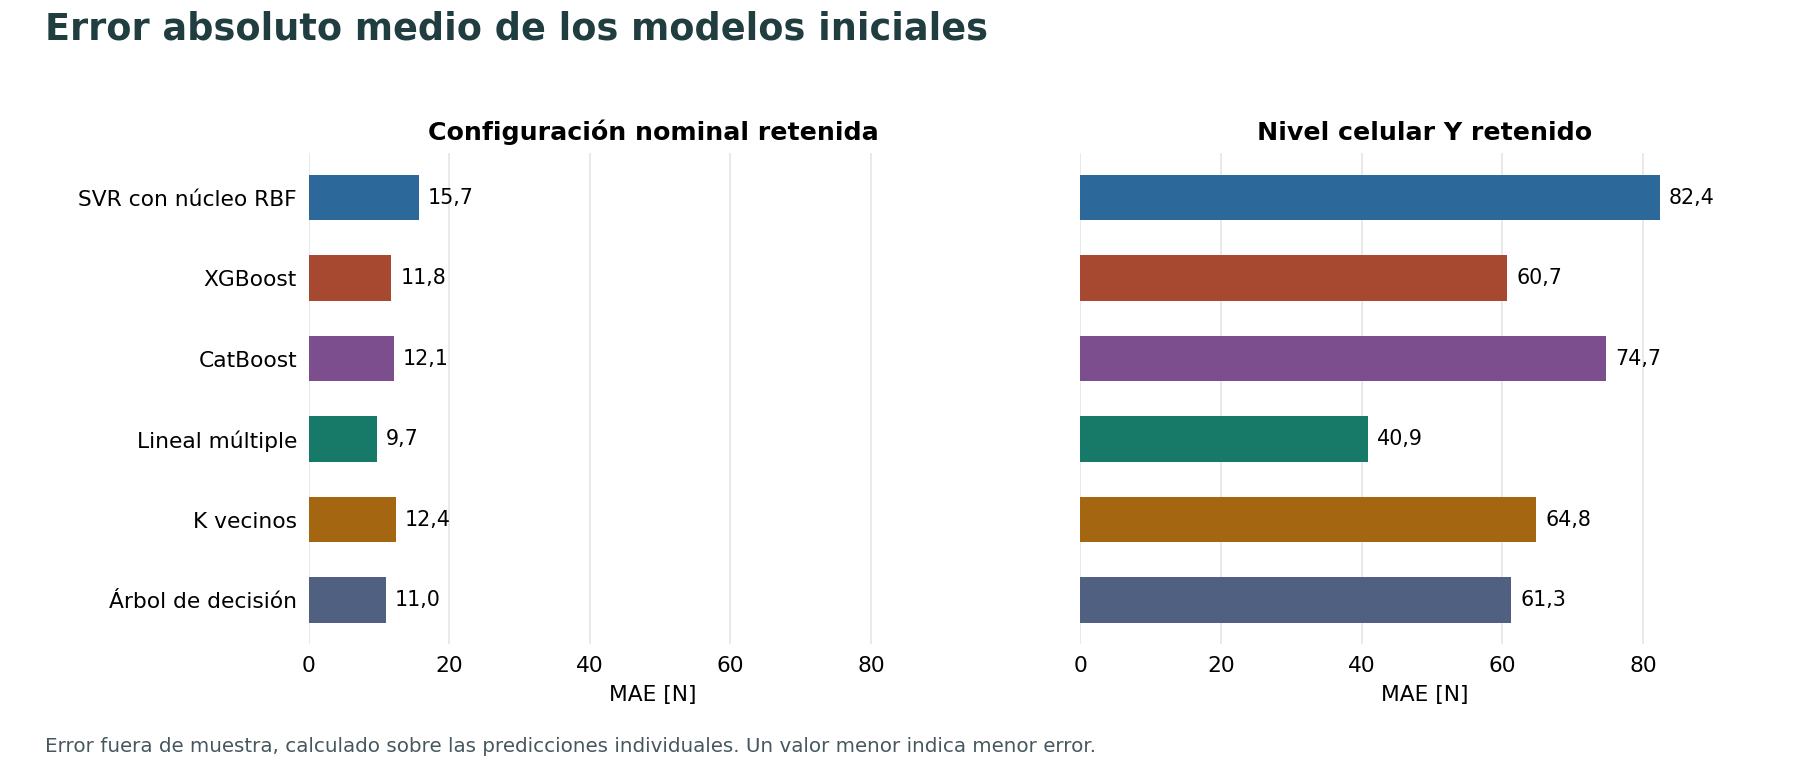

In [2]:
panel_mae = display(Markdown(""), display_id=True)

### Figura 2. Carga observada frente a la carga predicha

Cada marca representa medias en un cuartil de carga observada. Una curva por debajo de la diagonal indica subestimación en ese tramo.

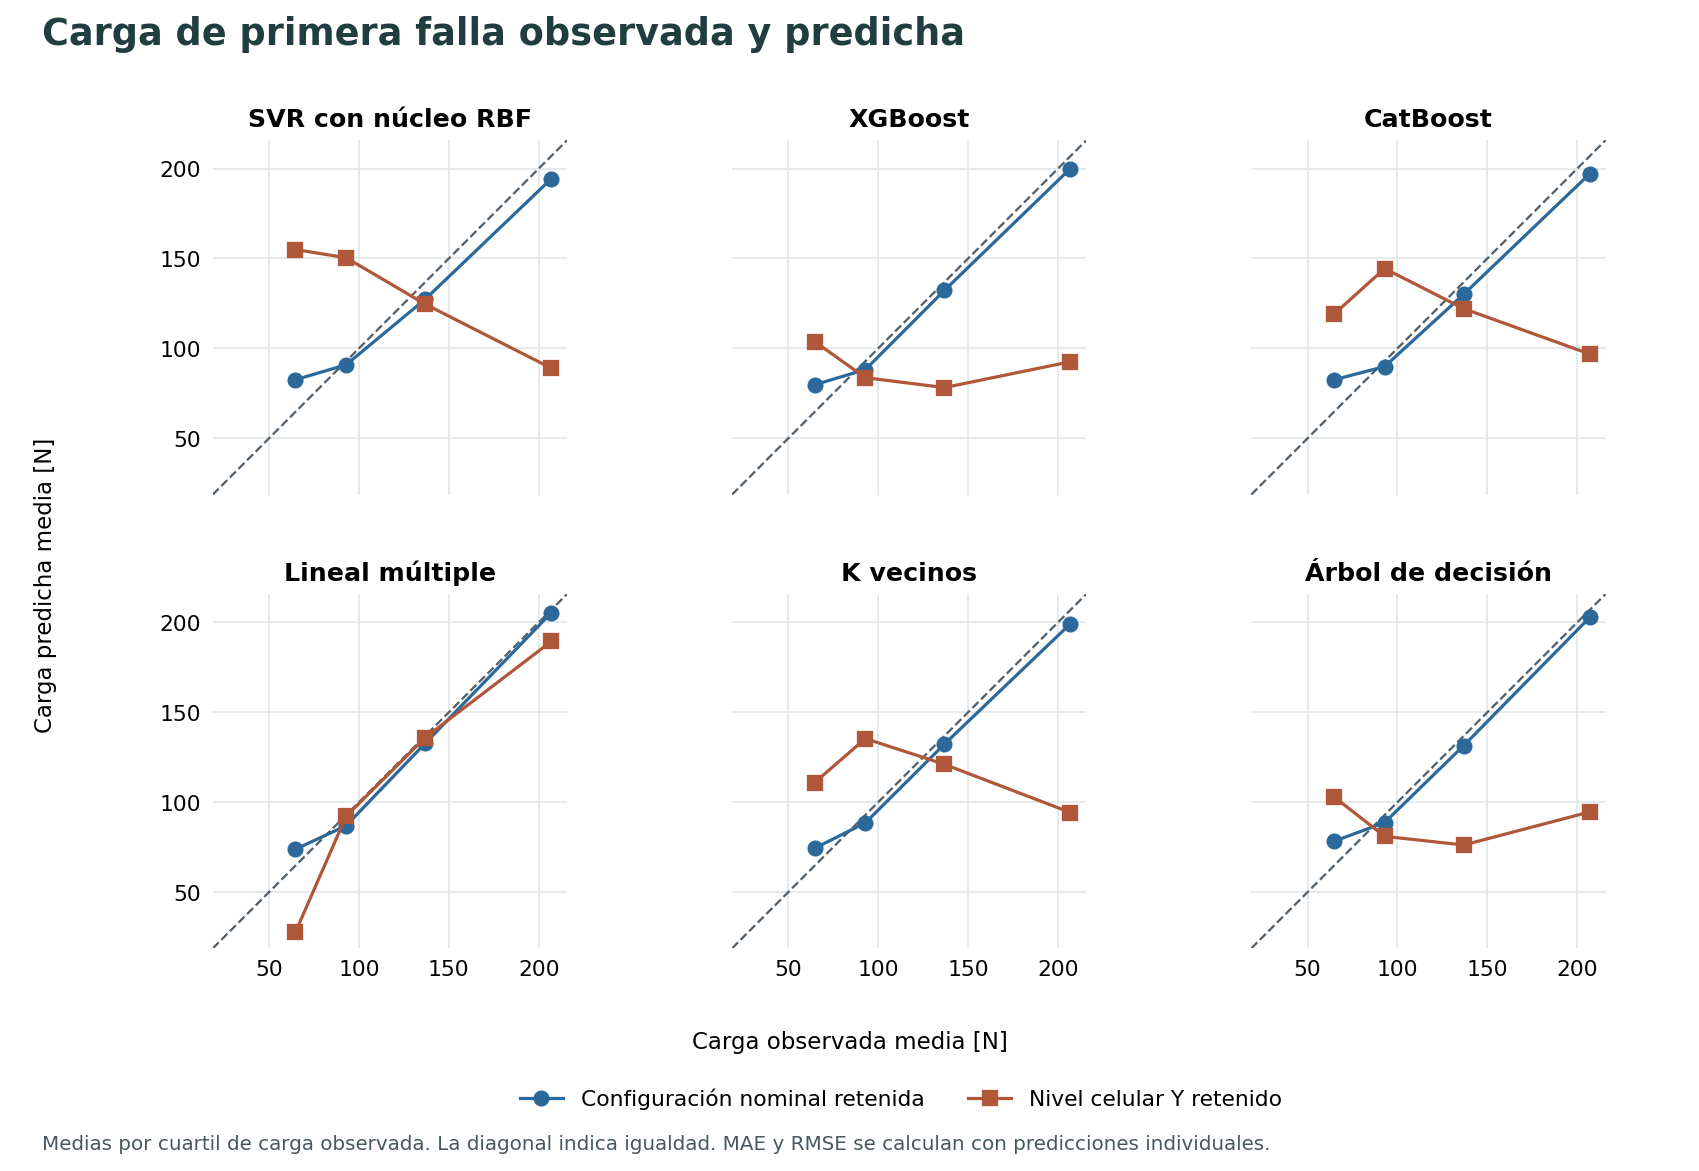

In [3]:
panel_carga = display(Markdown(""), display_id=True)

In [4]:
panel_comparaciones = display(Markdown(""), display_id=True)

### Baselines

| Referencia | MAE [N] | RMSE [N] | R² | MAE nivel Y [N] |
| :--- | ---: | ---: | ---: | ---: |
| Media por nivel Y | 10,126 | 12,308 | 0,956 | 80,593 |
| Ridge histórico | 13,247 | 16,346 | 0,923 | 57,637 |
| Mediana de entrenamiento | 49,748 | 64,699 | -0,213 | 97,511 |

### MAE antes y después del ajuste de hiperparámetros

Las columnas inicial y ajustada comparan la misma familia sobre las mismas probetas.

| Procedimiento | Config. inicial [N] | Config. ajustada [N] | Nivel Y inicial [N] | Nivel Y ajustada [N] |
| :--- | ---: | ---: | ---: | ---: |
| Primera del cribado | 11,095 | 11,263 | 82,358 | 81,106 |
| Segunda del cribado | 13,356 | 13,749 | 76,193 | 73,887 |
| Selector interno | 12,365 | 12,998 | 82,358 | 81,106 |

Al reservar configuraciones, el MAE del selector aumentó en 0,633 N.

## Método de evaluación

Se comparan seis regresores con los mismos predictores geométricos y las mismas reservas externas. El baseline es la media de entrenamiento por nivel celular, junto a la mediana global y Ridge histórico. La comparación inicial usa parámetros fijos.

**Método de ajuste:** búsqueda aleatoria discreta sin reemplazo, con validación cruzada anidada por grupos. Dentro de cada entrenamiento externo se eligen dos familias y se ensayan ocho configuraciones por familia. La reserva externa se emplea exclusivamente para medir el error final. El apartado 5 detalla el muestreo, el criterio de elección y los desempates.

## 1. Datos y particiones

### 1.1 Respuesta y fuentes

La respuesta es la fuerza registrada en la primera rotura de fibra o pivote, en newtons. Se conservan las probetas con carga de primera falla observada. Los datos y las particiones se recuperan de la copia versionada incluida en el cuaderno.

In [5]:
from __future__ import annotations

from io import BytesIO
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from IPython.display import Image

In [6]:
# Insumos previos al benchmark: casos medidos, definiciones y antecedentes.
from io import StringIO
from pathlib import Path
from urllib.request import urlopen

REVISION_DATOS = "ed6cd3385bf3e282535804c61d341e008627ab16"
URL_DATOS = f"https://raw.githubusercontent.com/melissaaylasb-sudo/T02_MIA14_SeccionB/{REVISION_DATOS}/"
ARCHIVOS = {
    "muestras": "data/processed/preliminary/model_table.csv",
    "features": "docs/benchmark/features.csv",
    "particiones": "reports/permutation_importance/tables/particiones_externas.csv",
    "historia": "docs/benchmark/antecedentes_metricas.csv",
    "previo": "reports/permutation_importance/tables/metricas_resumen.csv",
    "decisiones_fe": "reports/feature_engineering/tables/decisiones.csv",
    "historico_oof": "reports/feature_engineering/tables/predicciones_modelos_oof.csv",
    "experimento": "config/benchmark_regresion.json",
    "politica": "config/lectura_benchmark_regresion.json",
}

In [7]:
# Prioridad: checkout completo, copia adjunta al notebook y revisión fija en GitHub.
RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / ARCHIVOS["experimento"]).is_file()), None)

def fuentes_del_notebook() -> dict:
    """Encuentra la copia en el .ipynb original o en el único .ipynb de la carpeta."""
    original = Path("Comparativa_6_Modelos_Regresion_Pantograficas.ipynb")
    candidatos = [original] if original.is_file() else list(Path.cwd().glob("*.ipynb"))
    if len(candidatos) == 1:
        archivo = json.loads(candidatos[0].read_text(encoding="utf-8-sig"))
        return archivo.get("metadata", {}).get("fuentes_benchmark", {})
    return {}

copia = fuentes_del_notebook() if RAIZ is None else {}
if copia and copia.get("revision") != REVISION_DATOS:
    raise ValueError("La revisión de la copia adjunta al notebook difiere del protocolo.")
ORIGEN_INSUMOS = "checkout local" if RAIZ is not None else (
    "copia del notebook" if copia else "GitHub (revisión fijada)"
)

In [8]:
# Comprueba la identidad de las fuentes antes de preparar los datos.
def texto_fuente(ruta: str) -> str:
    """Lee UTF-8 y normaliza los saltos de línea para comparar Windows y Linux."""
    try:
        if RAIZ is not None:
            contenido = (RAIZ / ruta).read_bytes()
        elif copia:
            return copia["archivos_utf8"][ruta]
        else:
            with urlopen(URL_DATOS + ruta, timeout=20) as respuesta:
                contenido = respuesta.read()
    except (OSError, KeyError) as exc:
        raise RuntimeError(
            f"No se pudo leer {ruta} desde {ORIGEN_INSUMOS}. Usa el notebook publicado "
            "completo, su checkout o una conexión a GitHub."
        ) from exc
    return contenido.decode("utf-8-sig").replace("\r\n", "\n")

entradas = {k: texto_fuente(ruta) for k, ruta in ARCHIVOS.items()}
huellas_entradas = {k: hashlib.sha256(t.encode()).hexdigest() for k, t in entradas.items()}
manifiesto = "\n".join(sorted(f"{ARCHIVOS[k]} {sha}" for k, sha in huellas_entradas.items()))
if hashlib.sha256(manifiesto.encode()).hexdigest() != "380a01040414da69be5e568dfee9a5c3cc1e95893af5ccad5e0f0e5808ec387c":
    raise ValueError(f"Algún insumo difiere de la revisión {REVISION_DATOS[:7]}. "
                     "Revisa los cambios locales antes de comparar métricas.")

In [9]:
def tabla_fuente(nombre: str) -> pd.DataFrame:
    """Conserva la precisión de las mediciones y de los controles históricos."""
    return pd.read_csv(StringIO(entradas[nombre]), float_precision="round_trip")

muestras = tabla_fuente("muestras")
features = tabla_fuente("features")
particiones = tabla_fuente("particiones")
historia = tabla_fuente("historia")
previo = tabla_fuente("previo")
decisiones_fe = tabla_fuente("decisiones_fe")

# Estas predicciones anteriores permiten comprobar la continuidad de Ridge y SVR.
historico_oof = tabla_fuente("historico_oof")
historico_oof = historico_oof.loc[
    historico_oof["modelo"].isin(["SVR_RBF", "Ridge"]),
    ["protocolo", "fold", "Case_n", "modelo", "predicho_N"]
].reset_index(drop=True)

CFG = json.loads(entradas["experimento"])
LECTURA = json.loads(entradas["politica"])
target = CFG["target"]
grupo_cols = ["n_cells_Y", "Fiber_height", "Pivot_height"]
GEOMETRY = features["Feature"].tolist()

In [10]:
# Nombres de modelos, protocolos y leyendas compartidas.
MODELOS = ("SVR_RBF", "XGBoost", "CatBoost", "Lineal_multiple", "KNN", "Arbol_decision")
PROTOCOLOS = ("configuracion", "familia")
PROTO = {"configuracion": "Configuración nominal retenida", "familia": "Nivel celular Y retenido"}
NOMBRES = {
    "SVR_RBF": "SVR con núcleo RBF",
    "XGBoost": "XGBoost",
    "CatBoost": "CatBoost",
    "Lineal_multiple": "Lineal múltiple",
    "KNN": "K vecinos",
    "Arbol_decision": "Árbol de decisión",
    "Dummy_mediana": "Mediana de entrenamiento",
    "Media_por_nivel": "Media por nivel Y",
    "Ridge_historico": "Ridge histórico",
    "Tuning_rango_1": "Primera del cribado",
    "Tuning_rango_2": "Segunda del cribado",
    "Selector_tuning": "Selector interno",
}

In [11]:
def fmt(x, posiciones=2):
    return f"{float(x):.{posiciones}f}".replace(".", ",")


def nombre(codigo):
    return NOMBRES.get(codigo, str(codigo))


def formato_celda(valor):
    if isinstance(valor, (float, np.floating)):
        return fmt(valor, 3) if np.isfinite(valor) else "—"
    if valor is None:
        return "—"
    return str(valor).replace("|", r"\|").replace("\n", " ")


def tabla_markdown(datos):
    """Crea una tabla Markdown, con las métricas alineadas a la derecha."""
    def fila(valores):
        return "| " + " | ".join(formato_celda(v) for v in valores) + " |"

    alineacion = ["---:" if pd.api.types.is_numeric_dtype(tipo) else ":---"
                  for tipo in datos.dtypes]
    filas = [fila(datos.columns), fila(alineacion)]
    filas.extend(fila(valores) for valores in datos.itertuples(index=False, name=None))
    return "\n".join(filas)


def tabla(datos):
    display(Markdown(tabla_markdown(datos)))

In [12]:
def nota(texto):
    display(Markdown(texto))


def detalle(titulo, datos):
    display(Markdown(f"**{titulo}**\n\n" + tabla_markdown(datos)))

### 1.2 Geometría admisible antes del ensayo

La representación A utiliza dimensiones y conteos de fibras, pivotes y celdas. Se excluyen el identificador, la carga terminal, las energías y los desplazamientos registrados durante el ensayo. Cada variable conserva la unidad documentada en la fuente.

In [13]:
predictores = features["Feature"].tolist()
assert target == "First_Failure_Load_N" and CFG["unidad"] == "N"
assert len(predictores) == len(set(predictores)) and set(predictores).issubset(muestras)
assert not set(predictores).intersection({target, "Case_n", "__source_record", "Ultimate_Load", "Maximum_Displacement"})
assert muestras.Case_n.is_unique and muestras[target].notna().all()

In [14]:
# La representación A conserva las medidas geométricas y las unidades de la fuente.
tabla(features[["Feature", "Unidad", "Justificación física"]].rename(columns={
    "Feature": "Variable", "Justificación física": "Medida geométrica"
}))
detalle("Variantes geométricas B–D y motivo para conservar A", decisiones_fe[[
    "experimento", "referencia", "intervencion", "delta_MAE_N", "decision"
]])

| Variable | Unidad | Medida geométrica |
| :--- | :--- | :--- |
| n_cells_Y | conteo | Número de celdas en la dirección Y; indicador de la arquitectura. |
| Fiber_height | mm | Altura de la sección de las fibras. |
| Fiber_base | mm | Ancho de sección; algunas fuentes geométricas discrepan. |
| Fiber_total_length | mm | Longitud declarada del conjunto de fibras, vinculada al nivel Y. |
| Fiber_total_volume | mm³ | Volumen declarado de fibras; relacionado con el de pivotes. |
| Pivot_height | mm | Altura nominal de los elementos de unión. |
| Pivot_radius | mm | Radio nominal del pivote; constante en la campaña. |
| Pivot_total_number | conteo | Cantidad de conexiones; depende de la arquitectura observada. |
| Pivot_total_volume | mm³ | Volumen declarado del conjunto de uniones. |
| Sample_total_volume | mm³ | Volumen declarado del espécimen según CAD; no se sustituye por una suma. |

**Variantes geométricas B–D y motivo para conservar A**

| experimento | referencia | intervencion | delta_MAE_N | decision |
| :--- | :--- | :--- | ---: | :--- |
| B | A | Añadir dos segundos momentos de área de la sección de fibra | -0,412 | Mantener en evaluación |
| C | B | Añadir ln(volumen_pivotes / volumen_fibras) | 0,079 | Descartar |
| D | C | Retirar longitud total de fibras, número de pivotes y volumen de fibras del bloque original | 4,121 | Descartar |

### 1.3 Qué se reserva en cada protocolo

| Protocolo | Grupo que sale del entrenamiento | Alcance de la predicción |
|---|---|---|
| Configuración nominal | Combinación de celdas en Y, altura de fibra y altura de pivote. | Otra configuración de un nivel celular conocido. |
| Nivel celular Y | Todas las probetas del nivel retenido. | Transferencia a un nivel ausente. Un nivel intermedio y uno extremo plantean problemas distintos. |

Las probetas con la misma clave nominal se reservan juntas para evitar que esa configuración aparezca a ambos lados. La evidencia disponible no permite tratarlas como réplicas de fabricación confirmadas.

In [15]:
for _, fila in particiones.iterrows():
    train, test = [set(map(int,str(fila[k]).split(";"))) for k in ("casos_train","casos_test")]
    assert not train & test and train | test == set(muestras.Case_n)

## 2. Baselines

Se recalculan tres referencias en cada reserva. La mediana usa todas las cargas de entrenamiento. La media por nivel usa las cargas de entrenamiento del mismo Y y recurre a la media global cuando falta ese nivel. Ridge emplea la geometría A. Las variables prioritarias del estudio anterior cambiaban según el modelo y el pliegue.

### 2.1 Resultados comparables del estudio anterior

Se recuperan los resultados previos bajo sus propios protocolos antes de recalcular las referencias.

In [16]:
# Antecedentes separados del experimento actual.
antecedentes = previo.loc[
    ((previo.modelo.isin(["Ridge", "SVR_RBF"])) & (previo.conjunto == "todas"))
    | (previo.modelo == "Media_por_nivel"),
    ["protocolo", "modelo", "MAE_N", "RMSE_N", "R2"]
]
detalle("Métricas del estudio anterior", antecedentes)
inventario = historia.groupby("etapa", sort=False)["modelo"].agg(
    lambda grupo: ", ".join(pd.unique(grupo))
).rename("Modelos evaluados").reset_index()
detalle("Modelos evaluados por etapa previa", inventario)

**Métricas del estudio anterior**

| protocolo | modelo | MAE_N | RMSE_N | R2 |
| :--- | :--- | ---: | ---: | ---: |
| configuracion | Ridge | 13,247 | 16,346 | 0,923 |
| configuracion | SVR_RBF | 15,651 | 19,096 | 0,894 |
| configuracion | Media_por_nivel | 10,126 | 12,308 | 0,956 |
| familia | Ridge | 57,637 | 60,428 | -0,058 |
| familia | SVR_RBF | 82,358 | 88,039 | -1,246 |
| familia | Media_por_nivel | 80,593 | 87,521 | -1,219 |

**Modelos evaluados por etapa previa**

| etapa | Modelos evaluados |
| :--- | :--- |
| 04 · variantes | Media de entrenamiento, Ridge(alpha=1, solver=svd) |
| 04 · familias fijas | Ridge, ElasticNet, SVR_RBF, RandomForest, GaussianProcess |
| 05 · ajuste anidado | Baseline_Ridge, Ridge, ElasticNet, SVR_RBF, RandomForest, ExtraTrees, GaussianProcess, GradientBoosting, Selector_interno |
| 06 · importancia anterior | Dummy, Ridge, ElasticNet |
| 06 · permutación | Ridge, ElasticNet, SVR_RBF, RandomForest, GaussianProcess, Mediana, Media_por_nivel |

### 2.2 Cálculo de las referencias dentro del entrenamiento

La referencia por nivel solo usa las cargas del entrenamiento. Cuando el nivel reservado está ausente, utiliza la media global de ese entrenamiento.

In [17]:
from time import perf_counter
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted
from threadpoolctl import threadpool_limits


class MeanByLevel(RegressorMixin, BaseEstimator):
    """Media Y de train; si falta el nivel usa la media global del mismo train."""

    def fit(self, X: pd.DataFrame, y: np.ndarray):
        self.global_mean_ = float(np.mean(y))
        self.means_ = pd.Series(np.asarray(y)).groupby(X.n_cells_Y.to_numpy()).mean().to_dict()
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        check_is_fitted(self, 'means_')
        return X.n_cells_Y.map(self.means_).fillna(self.global_mean_).to_numpy(float)

In [18]:
def referencia_inicial(familia):
    parametros = CFG["parametros_iniciales"][familia]
    if familia == "Dummy_mediana":
        return Pipeline([("model", DummyRegressor(**parametros))])
    if familia == "Media_por_nivel":
        return Pipeline([("model", MeanByLevel())])
    if familia != "Ridge_historico":
        raise ValueError(f"Referencia inesperada: {familia}")
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("variance", VarianceThreshold()),
        ("scale", StandardScaler()),
        ("model", Ridge(**parametros)),
    ])

def casos_de(texto):
    return [int(caso) for caso in str(texto).split(";")]

In [19]:
casos = muestras.set_index("Case_n").sort_index()
X_base, y_base = casos[predictores], casos[target]
ajustes_base, predicciones_base = {}, []
with threadpool_limits(limits=1):
    for reserva in particiones.itertuples():
        train, test = casos_de(reserva.casos_train), casos_de(reserva.casos_test)
        assert set(train).isdisjoint(test)
        for familia in CFG["referencias"]:
            modelo = referencia_inicial(familia)
            inicio = perf_counter()
            modelo.fit(X_base.loc[train], y_base.loc[train])
            t_fit = perf_counter() - inicio
            inicio = perf_counter()
            pred = modelo.predict(X_base.loc[test])
            t_pred = perf_counter() - inicio
            clave = (reserva.protocolo, reserva.fold, familia)
            ajustes_base[clave] = (modelo, t_fit, pred, t_pred, modelo.predict(X_base.loc[train]))
            for caso, valor_predicho in zip(test, pred):
                predicciones_base.append((reserva.protocolo, familia, caso, y_base.at[caso], valor_predicho))

### 2.3 Error externo de los baselines

Se calcula la diferencia absoluta entre la predicción reservada y la carga registrada, y se promedia por protocolo.

In [20]:
base_oof = pd.DataFrame(predicciones_base, columns=["protocolo", "referencia", "caso", "observado_N", "predicho_N"])
base_oof["error_absoluto_N"] = (base_oof.predicho_N - base_oof.observado_N).abs()
assert not base_oof.duplicated(["protocolo", "referencia", "caso"]).any()
resumen_base = base_oof.groupby(["protocolo", "referencia"]).agg(
    casos=("caso", "size"), MAE_N=("error_absoluto_N", "mean")
)
assert resumen_base.casos.eq(len(casos)).all()
mae_por_escenario = resumen_base.MAE_N.unstack("protocolo").rename(index=nombre)
tabla(mae_por_escenario.rename(columns={"configuracion": "Configuración · MAE [N]",
      "familia": "Nivel Y · MAE [N]"}).rename_axis("Referencia").reset_index())
nivel = resumen_base.xs("Media_por_nivel", level="referencia").MAE_N
nota(f"Con el nivel Y presente en entrenamiento, la media por nivel tiene un error de {fmt(nivel['configuracion'])} N. "
     f"Al reservar el nivel completo, la media de entrenamiento da {fmt(nivel['familia'])} N.")

| Referencia | Configuración · MAE [N] | Nivel Y · MAE [N] |
| :--- | ---: | ---: |
| Mediana de entrenamiento | 49,748 | 97,511 |
| Media por nivel Y | 10,126 | 80,593 |
| Ridge histórico | 13,247 | 57,637 |

Con el nivel Y presente en entrenamiento, la media por nivel tiene un error de 10,13 N. Al reservar el nivel completo, la media de entrenamiento da 80,59 N.

## 3. Seis modelos y su preprocesamiento

SVR, XGBoost y CatBoost se han comparado en retículas impresas. También hay antecedentes en templabilidad del acero y resistencia a cortante del hormigón. Las propiedades y las condiciones de carga difieren de las de estas probetas. [Huang et al.](https://doi.org/10.1007/s40964-025-01409-6) · [Nenchev et al.](https://doi.org/10.1007/s12613-022-2437-0) · [Megahed](https://doi.org/10.1038/s41598-024-64386-w) · [Revisión sobre datos pequeños en materiales](https://doi.org/10.1038/s41524-023-01000-z)

| Modelo | Qué contrasta | Parámetros que controlan el ajuste |
|---|---|---|
| SVR-RBF | Una relación geométrica suave. | Penalización C, banda ε en N y alcance del núcleo γ. |
| XGBoost | Interacciones aprendidas con árboles sucesivos. | Rondas, profundidad, tasa de aprendizaje, peso mínimo de hijo y penalización de hoja. |
| CatBoost | Boosting con árboles simétricos sobre entradas numéricas. | Iteraciones, profundidad, tasa de aprendizaje y contracción L2 de hojas. |
| Lineal múltiple | Cuánta precisión aporta una combinación lineal. | Mínimos cuadrados con intercepto. La colinealidad limita la interpretación de pendientes. |
| K vecinos | Si geometrías próximas presentan cargas semejantes. | Número de vecinos, ponderación y distancia. |
| Árbol de decisión | Cuánta señal captan unas pocas divisiones geométricas. | Profundidad y tamaño mínimo de hoja. Los cortes dependen de los especímenes de entrenamiento. |

### 3.1 Comparabilidad de las particiones

Todas las familias reciben la misma geometría. Los identificadores sirven para reconstruir la separación entre entrenamiento y prueba.

In [21]:
from collections import defaultdict
from itertools import product
from typing import Any
import warnings

from sklearn.base import TransformerMixin
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, export_text
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

GEOMETRY, TARGET, GROUP_COLUMNS = predictores, target, grupo_cols
cfg = CFG
INITIAL, REFS = tuple(cfg["familias"]), tuple(cfg["referencias"])
ADAPT = ("Tuning_rango_1", "Tuning_rango_2", "Selector_tuning")
UNITS = dict(zip(features.Feature, features.Unidad))
Params = dict[str, Any]
Rows = dict[str, list[dict[str, Any]]]
assert INITIAL == MODELOS and len(GEOMETRY) == len(set(GEOMETRY)) == 10

In [22]:
def nominal_groups(frame, columns):
    if frame[columns].isna().any().any():
        raise ValueError('No se pueden verificar grupos nominales con claves ausentes.')
    return frame[columns].apply(lambda row: '|'.join((format(float(v), '.12g') for v in row)), axis=1)


frame = muestras.copy().sort_values("Case_n").reset_index(drop=True)
assert "Case_n" in frame and frame.Case_n.is_unique and not frame.Case_n.isna().any()
frame = frame.loc[frame[TARGET].notna()].reset_index(drop=True)
assert np.isfinite(frame[TARGET]).all() and (frame[TARGET] > 0).all()
X = frame.set_index("Case_n")[GEOMETRY]
y = frame.set_index("Case_n")[TARGET]
nominal = nominal_groups(frame, GROUP_COLUMNS).to_numpy()
indices = {int(case): i for i, case in enumerate(X.index)}

In [23]:
def indices_casos(values):
    if isinstance(values, str):
        values = values.split(";")
    return np.array([indices[int(case)] for case in values], dtype=int)

splits = {}
for protocol in cfg["protocolos"]:
    folds = particiones.loc[particiones.protocolo == protocol].sort_values("fold")
    assert folds.fold.tolist() == list(range(1, len(folds) + 1))
    splits[protocol] = [(indices_casos(r.casos_train), indices_casos(r.casos_test)) for r in folds.itertuples()]
    groups = nominal if protocol == "configuracion" else X.n_cells_Y.to_numpy()
    evaluated = []
    for tr, te in splits[protocol]:
        assert not set(tr) & set(te) and set(tr) | set(te) == set(range(len(X)))
        assert not set(groups[tr]) & set(groups[te]) and len(set(groups[te])) == 1
        evaluated.extend(te)
    assert sorted(evaluated) == list(range(len(X)))
assert len(splits["configuracion"]) == len(np.unique(nominal))
assert len(splits["familia"]) == X.n_cells_Y.nunique()

### 3.2 Configuraciones iniciales

Los seis modelos usan las mismas variables de la representación A. Las medianas para imputación, el filtro de constantes y la escala se aprenden en cada entrenamiento. SVR, K vecinos y mínimos cuadrados emplean variables estandarizadas. En mínimos cuadrados se conservan, en su orden original, las columnas que aumentan el rango numérico de la matriz centrada (tolerancia relativa `1e−10`). El radio del pivote es constante en esta campaña.

In [24]:
def ficha_corta(m):
    p = CFG["parametros_iniciales"].get(m, {})
    if m == "SVR_RBF": return f"RBF, C={p['C']:g}, ε={p['epsilon']:g} N, γ={p['gamma']}"
    if m == "XGBoost": return f"{p['n_estimators']} árboles, profundidad {p['max_depth']}, η={p['learning_rate']}"
    if m == "CatBoost": return f"{p['iterations']} iteraciones, profundidad {p['depth']}, η={p['learning_rate']}"
    if m == "KNN": return f"k={p['n_neighbors']}, p={p['p']}, pesos {p['weights']}"
    if m == "Arbol_decision": return f"Profundidad {p['max_depth']}, hoja mínima {p['min_samples_leaf']}"
    if m == "Lineal_multiple": return "Mínimos cuadrados con intercepto y base de rango completo"
    if m == "Ridge_historico": return f"α={p['alpha']:g}, solucionador {p['solver']}"
    if m == "Media_por_nivel": return "Media por Y, con media de entrenamiento para nivel ausente"
    if m == "Dummy_mediana": return "Mediana del entrenamiento"
    return "Familia y parámetros elegidos dentro del entrenamiento"

In [25]:
tabla(pd.DataFrame([{"Modelo": nombre(m), "Receta inicial": ficha_corta(m)} for m in MODELOS]))
detalle("Configuración completa y semillas", pd.DataFrame([
    {"Modelo": nombre(m), "Parámetros": json.dumps(CFG["parametros_iniciales"][m], ensure_ascii=False)}
    for m in MODELOS
]))

| Modelo | Receta inicial |
| :--- | :--- |
| SVR con núcleo RBF | RBF, C=100, ε=5 N, γ=scale |
| XGBoost | 60 árboles, profundidad 2, η=0.075 |
| CatBoost | 60 iteraciones, profundidad 2, η=0.075 |
| Lineal múltiple | Mínimos cuadrados con intercepto y base de rango completo |
| K vecinos | k=3, p=2, pesos uniform |
| Árbol de decisión | Profundidad 2, hoja mínima 2 |

**Configuración completa y semillas**

| Modelo | Parámetros |
| :--- | :--- |
| SVR con núcleo RBF | {"kernel": "rbf", "C": 100.0, "epsilon": 5.0, "gamma": "scale"} |
| XGBoost | {"objective": "reg:squarederror", "n_estimators": 60, "max_depth": 2, "learning_rate": 0.075, "min_child_weight": 2, "reg_lambda": 3, "reg_alpha": 0, "subsample": 1, "colsample_bytree": 1, "tree_method": "hist", "n_jobs": 1, "random_state": 42, "verbosity": 0} |
| CatBoost | {"loss_function": "RMSE", "iterations": 60, "depth": 2, "learning_rate": 0.075, "l2_leaf_reg": 5, "random_strength": 0, "bootstrap_type": "No", "thread_count": 1, "allow_writing_files": false, "verbose": false, "random_seed": 42} |
| Lineal múltiple | {"fit_intercept": true} |
| K vecinos | {"n_neighbors": 3, "weights": "uniform", "metric": "minkowski", "p": 2, "algorithm": "brute", "n_jobs": 1} |
| Árbol de decisión | {"criterion": "squared_error", "max_depth": 2, "min_samples_leaf": 2, "random_state": 42} |

### 3.3 Transformaciones dentro de cada entrenamiento

Se valida la geometría disponible. Para la regresión lineal se comprueba el rango tras centrar y escalar las entradas. La imputación, el filtro de constantes y el escalado se vuelven a ajustar en cada pliegue que los requiere.

In [26]:
class GeometryContract(TransformerMixin, BaseEstimator):
    """Rechaza respuestas, identificadores, infinitos y geometrías no positivas.

    Se admiten NaN en transform para imputación con estadísticas de entrenamiento.
    Una columna completamente ausente en entrenamiento no permite estimar mediana.
    """

    def _validate(self, X):
        if not isinstance(X, pd.DataFrame) or set(X.columns) != set(GEOMETRY) or X.columns.duplicated().any():
            raise ValueError('Se requieren exclusivamente las columnas geométricas autorizadas; sin target ni identificadores.')
        x = X[GEOMETRY].apply(pd.to_numeric, errors='raise').astype(float)
        a = x.to_numpy()
        if np.isinf(a).any() or (a <= 0).any():
            raise ValueError('La geometría debe ser positiva y finita, o NaN para imputación.')
        for col in ['n_cells_Y', 'Pivot_total_number']:
            v = x[col].dropna().to_numpy()
            if not np.equal(v, np.floor(v)).all():
                raise ValueError('Los conteos geométricos deben ser enteros.')
        return x

    def fit(self, X, y=None):
        x = self._validate(X)
        if x.isna().all().any():
            raise ValueError('Una entrada carece de observaciones en entrenamiento.')
        self.feature_names_in_ = np.array(GEOMETRY, dtype=object)
        self.n_features_in_ = len(GEOMETRY)
        return self

    def transform(self, X):
        check_is_fitted(self)
        return self._validate(X)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self)
        return self.feature_names_in_.copy()

In [27]:
class FullRankBasis(TransformerMixin, BaseEstimator):
    """Base no supervisada de la matriz de diseño centrada, aprendida solo en fit."""

    def __init__(self, rtol: float=1e-10):
        self.rtol = rtol

    def fit(self, X: np.ndarray, y: np.ndarray | None=None):
        a = np.asarray(X, dtype=float)
        a = a - a.mean(axis=0)
        self.singular_values_ = np.linalg.svd(a, compute_uv=False)
        self.tol_ = float(self.rtol * self.singular_values_[0])
        selected = []
        for i in range(a.shape[1]):
            if np.linalg.matrix_rank(a[:, selected + [i]], tol=self.tol_) > len(selected):
                selected.append(i)
        if not selected:
            raise ValueError('Diseño OLS sin columnas informativas.')
        self.indices_ = np.asarray(selected, dtype=int)
        self.n_features_in_ = a.shape[1]
        self.rank_ = int(np.linalg.matrix_rank(a, tol=self.tol_))
        if self.rank_ != len(selected):
            raise ValueError('Base secuencial numéricamente ambigua; revisar la tolerancia.')
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        check_is_fitted(self, 'indices_')
        return np.asarray(X)[:, self.indices_]

In [28]:
def pipeline(family: str, params: Params, cfg: Params) -> Pipeline:
    if family in REFS:
        return referencia_inicial(family)
    constructores = {
        "SVR_RBF": SVR, "XGBoost": XGBRegressor, "CatBoost": CatBoostRegressor,
        "Lineal_multiple": LinearRegression, "KNN": KNeighborsRegressor,
        "Arbol_decision": DecisionTreeRegressor,
    }
    pasos = [
        ("contract", GeometryContract()),
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True).set_output(transform="pandas")),
        ("variance", VarianceThreshold()),
    ]
    if family in ("SVR_RBF", "KNN", "Lineal_multiple"):
        pasos.append(("scale", StandardScaler()))
    if family == "Lineal_multiple":
        pasos.append(("basis", FullRankBasis(cfg["ols"]["tolerancia_svd_relativa"])))
    return Pipeline([*pasos, ("model", constructores[family](**params))])

def feature_names(modelo):
    return np.array(GEOMETRY)[modelo.named_steps["variance"].get_support()]

## 4. Evaluación de los modelos iniciales

### 4.1 Entrenar y predecir en reservas externas

Cada modelo se ajusta con sus parámetros iniciales y predice las probetas reservadas. Las referencias calculadas en el apartado 2 se incorporan con sus predicciones originales.

In [29]:
def _object(value: Any) -> str:
    return json.dumps(value, ensure_ascii=False, sort_keys=True, allow_nan=False,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x))


def _ids(values: Any) -> str:
    return ';'.join((str(int(v)) for v in values))


def _stage(proc: str) -> str:
    return 'inicial' if proc in INITIAL else 'referencia' if proc in REFS else 'optimizada'


def _group(proc: str) -> str:
    if proc in REFS:
        return 'referencia'
    if proc in ADAPT:
        return 'procedimiento_adaptativo'
    return 'A_materiales' if proc in INITIAL[:3] else 'B_clasicos'

In [30]:
def metrics(y: np.ndarray, pred: np.ndarray) -> dict[str, float]:
    """Métricas en N; R² solo definido para al menos dos respuestas diferentes."""
    y = np.asarray(y, dtype=float)
    p = np.asarray(pred, dtype=float)
    if y.shape != p.shape or y.ndim != 1 or (not len(y)) or (not np.isfinite([y, p]).all()):
        raise ValueError('Respuestas/predicciones inválidas.')
    e = p - y
    a = np.abs(e)
    return {'MAE_N': float(a.mean()), 'RMSE_N': float(np.sqrt((e ** 2).mean())),
        'MedAE_N': float(np.median(a)),
        'R2_OOF': float(r2_score(y, p)) if len(y) > 1 and np.ptp(y) > 0 else np.nan, 'sesgo_N': float(e.mean())}


def _predict(obj: Any, X: pd.DataFrame) -> tuple[np.ndarray, float]:
    start = perf_counter()
    p = np.asarray(obj.predict(X), dtype=float).reshape(-1)
    seconds = perf_counter() - start
    if len(p) != len(X) or not np.isfinite(p).all():
        raise ValueError('Predicción no finita o de longitud incorrecta.')
    return (p, seconds)

In [31]:
def guardar_ajuste(family, params, X, context, rows, obj, seconds, avisos=""):
    record = {**context, 'familia_real': family, 'n_train': len(X), 'casos_train': _ids(X.index),
        'parametros_json': _object(params), 'tiempo_ajuste_s': seconds,
        'avisos': avisos}
    for step, field in [('imputer', 'statistics_'), ('scale', 'mean_'), ('scale', 'scale_')]:
        if step in obj.named_steps:
            record[step + field] = _object(getattr(obj.named_steps[step], field).tolist())
    rows['ajustes'].append(record)


def _fit(family: str, params: Params, cfg: Params, X: pd.DataFrame, y: pd.Series, context: Params,
    rows: Rows) -> tuple[Any, float]:
    if not X.index.equals(y.index) or not X.index.is_unique or set(X) != set(GEOMETRY):
        raise ValueError('Contrato de entrenamiento inválido.')
    if family == 'KNN' and params['n_neighbors'] > len(y):
        raise ValueError('k supera el train del pliegue.')
    obj = pipeline(family, params, cfg)
    start = perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        obj.fit(X, y)
    seconds = perf_counter() - start
    guardar_ajuste(family, params, X, context, rows, obj, seconds,
                   ' | '.join(sorted({str(w.message) for w in caught})))
    return obj, seconds

In [32]:
def _record(proc: str, family: str, stage_ctx: Params, X: pd.DataFrame, y: pd.Series, train: np.ndarray,
    test: np.ndarray, nominal: np.ndarray, p: np.ndarray, pt: np.ndarray, fit_s: float, predict_s: float,
    search_s: float, initial: np.ndarray, rows: Rows) -> None:
    ctx = {**stage_ctx, 'procedimiento': proc, 'etapa': _stage(proc), 'familia_real': family}
    yt = y.iloc[test].to_numpy()
    met = metrics(yt, p)
    rows['metricas_folds'].append({**ctx, 'n_train': len(train), 'n_test': len(test),
        'MAE_train_N': metrics(y.iloc[train].to_numpy(), pt)['MAE_N'], 'MAE_validacion_N': met['MAE_N'],
        'RMSE_validacion_N': met['RMSE_N'], 'MedAE_validacion_N': met['MedAE_N'],
        'sesgo_validacion_N': met['sesgo_N'], 'tiempo_ajuste_s': fit_s, 'tiempo_prediccion_s': predict_s,
        'tiempo_busqueda_s': search_s})
    for j, obs, pred, orig in zip(test, yt, p, initial):
        rows['predicciones_oof'].append({**ctx, 'Case_n': int(X.index[j]),
            'n_cells_Y': int(X.iloc[j].n_cells_Y), 'grupo_nominal': nominal[j], 'observado_N': obs,
            'predicho_N': pred, 'residuo_N': obs - pred, 'error_absoluto_N': abs(obs - pred),
            'predicho_inicial_misma_familia_N': orig})
    for j, pred in zip(train, pt):
        rows['predicciones_train'].append({**ctx, 'Case_n': int(X.index[j]), 'observado_N': y.iloc[j],
            'predicho_N': pred})

In [33]:
rows: Rows = defaultdict(list)
cache, ajustes_para_diagnostico = {}, []
started = perf_counter()
with threadpool_limits(limits=1):
    for protocolo, reservas in splits.items():
        for fold, (tr, te) in enumerate(reservas, 1):
            contexto = {"protocolo": protocolo, "fold": fold}
            rows["particiones_externas"].append({
                **contexto, "casos_train": _ids(X.index[tr]), "casos_test": _ids(X.index[te])
            })
            for familia in (*INITIAL, *REFS):
                parametros = cfg["parametros_iniciales"][familia]
                ajuste = {**contexto, "etapa_ajuste": "externa_inicial", "config_id": familia + "_00"}
                clave = (protocolo, fold, familia)
                if familia in REFS:
                    obj, t_fit, pred, t_pred, p_train = ajustes_base[clave]
                    guardar_ajuste(familia, parametros, X.iloc[tr], ajuste, rows, obj, t_fit)
                else:
                    obj, t_fit = _fit(familia, parametros, cfg, X.iloc[tr], y.iloc[tr], ajuste, rows)
                    pred, t_pred = _predict(obj, X.iloc[te])
                    p_train, _ = _predict(obj, X.iloc[tr])
                cache[clave] = pred
                _record(familia, familia, contexto, X, y, tr, te, nominal, pred, p_train, t_fit, t_pred, 0, pred, rows)
                ajustes_para_diagnostico.append((obj, familia, tr, te, {**contexto, "procedimiento": familia}))

### 4.2 Métricas fuera de muestra

El MAE es la media de los errores absolutos por probeta. El RMSE da mayor peso a errores grandes. El sesgo conserva el signo de predicción menos observación. El R² se calcula reuniendo las predicciones externas dentro de cada protocolo. Las figuras 1 y 2 muestran el MAE y la concordancia entre carga observada y predicha.

In [34]:
def _summarize(rows: Rows) -> None:
    oof = pd.DataFrame(rows['predicciones_oof'])
    folds = pd.DataFrame(rows['metricas_folds'])
    for (protocol, proc), g in oof.groupby(['protocolo', 'procedimiento'], sort=False):
        f = folds[(folds.protocolo == protocol) & (folds.procedimiento == proc)]
        summary = {**metrics(g.observado_N.to_numpy(), g.predicho_N.to_numpy()), 'protocolo': protocol,
            'procedimiento': proc, 'etapa': _stage(proc), 'grupo': _group(proc),
            'feature_set': 'A' if proc not in REFS[:2] else 'sin_geometria' if proc == REFS[0] else 'n_cells_Y', 'n': len(g), 'n_folds': len(f), 'DE_error_absoluto_N': g.error_absoluto_N.std(ddof=1), 'DE_MAE_fold_N': f.MAE_validacion_N.std(ddof=1), 'IQR_MAE_fold_N': f.MAE_validacion_N.quantile(0.75) - f.MAE_validacion_N.quantile(0.25), 'MAE_train_medio_N': f.MAE_train_N.mean(), 'tiempo_ajuste_s': f.tiempo_ajuste_s.sum(), 'tiempo_prediccion_s': f.tiempo_prediccion_s.sum(), 'tiempo_busqueda_s': f.tiempo_busqueda_s.sum()}
        for name, col in zip(REFS, ['dummy', 'media_nivel', 'Ridge']):
            ref = oof[(oof.protocolo == protocol) & (oof.procedimiento == name)]
            summary['delta_MAE_vs_' + col + '_N'] = summary['MAE_N'] - ref.error_absoluto_N.mean()
        summary['delta_MAE_vs_inicial_misma_familia_N'] = summary['MAE_N'] - np.abs(g.observado_N - g.predicho_inicial_misma_familia_N).mean()
        rows['metricas_resumen'].append(summary)

In [35]:
_summarize(rows)
metricas = pd.DataFrame(rows["metricas_resumen"])
folds = pd.DataFrame(rows["metricas_folds"])
oof = pd.DataFrame(rows["predicciones_oof"])
resultado = {"metricas": metricas, "folds": folds, "oof": oof}
assert len(oof) == len(X) * len(PROTOCOLOS) * (len(MODELOS) + len(REFS))
assert not oof.duplicated(["protocolo", "procedimiento", "Case_n"]).any()

def resumen(proto, procedimientos=MODELOS):
    filas = metricas[metricas.protocolo.eq(proto)].set_index("procedimiento")
    return filas.loc[list(procedimientos)]

def valor(proto, procedimiento, campo="MAE_N"):
    return float(resumen(proto, (procedimiento,)).iloc[0][campo])

principal = resumen("configuracion")
transferencia = resumen("familia")
mejor = principal.MAE_N.idxmin()
mas_estable = principal.DE_MAE_fold_N.idxmin()

In [36]:
COLORES = dict(zip(MODELOS, ("#2C699A", "#A74930", "#7D4E8D", "#177967", "#A56612", "#506080")))
AZUL, VERDE, GRIS = "#2C699A", "#247654", "#54616C"
TITULOS = (
    'Error absoluto medio de los modelos iniciales',
    'Carga de primera falla observada y predicha',
    'Raíz del error cuadrático medio de los modelos iniciales',
    'Error de ajuste y error de validación externa',
    'Distribución del error absoluto por espécimen',
    'Residuos de las predicciones iniciales',
    'Evolución de la búsqueda de hiperparámetros',
    'Diferencia de error frente a Ridge histórico',
    'Efecto del ajuste de hiperparámetros sobre el error externo',
    'Variación del error entre particiones externas',
)

def _filas(df: pd.DataFrame, proto: str, modelos: tuple[str, ...] = MODELOS) -> pd.DataFrame:
    return df[df.protocolo.eq(proto) & df.procedimiento.isin(modelos)]


def _estilo(ax: plt.Axes, axis: str = "x") -> None:
    ax.set_axisbelow(True)
    ax.grid(axis=axis, color="#E0E6E7", linewidth=0.7)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="both", length=0, pad=5)


def _numero(x: float, dec: int = 1) -> str:
    return f"{x:.{dec}f}".replace(".", ",")

In [37]:
def _encabezado(fig: plt.Figure, numero: int, nota: str) -> None:
    fig.suptitle(
        TITULOS[numero - 1],
        x=0.025,
        y=0.986,
        ha="left",
        va="top",
        fontsize=16,
        weight="bold",
        color="#203D40",
    )
    fig.text(0.025, 0.015, nota, ha="left", va="bottom", fontsize=8.7, color="#47575E")

# Los bytes de la figura se guardan en memoria antes de mostrarlos.
figuras = {}

def figura(numero, dibujar, *argumentos):
    estilo = {
        "font.family": "DejaVu Sans", "font.size": 9.5, "axes.titlesize": 11,
        "axes.titleweight": "bold", "figure.facecolor": "white",
    }
    with plt.rc_context(estilo):
        grafico = dibujar(resultado, *argumentos)
        try:
            with BytesIO() as buffer:
                grafico.savefig(buffer, format="png", dpi=165, facecolor="white")
                figuras[numero] = buffer.getvalue()
        finally:
            plt.close(grafico)
    imagen = Image(data=figuras[numero], format="png", width=1000)
    if numero in (1, 2):
        {1: panel_mae, 2: panel_carga}[numero].update(imagen)
    else:
        display(imagen)

In [38]:
def _barras(data: dict, metrica: str, numero: int) -> plt.Figure:
    metricas = data["metricas"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.65), sharex=True, sharey=True)
    ymax = max(_filas(metricas, p)[metrica].max() for p in PROTOCOLOS)
    y = np.arange(len(MODELOS))
    for ax, p in zip(axes, PROTOCOLOS):
        rows = _filas(metricas, p).set_index("procedimiento").loc[list(MODELOS)]
        bars = ax.barh(y, rows[metrica], height=0.56, color=[COLORES[m] for m in MODELOS])
        ax.bar_label(bars, labels=[_numero(v) for v in rows[metrica]], padding=4, fontsize=9)
        ax.set(
            title=PROTO[p],
            xlabel=f"{metrica.split('_')[0]} [N]",
            xlim=(0, ymax * 1.19),
            yticks=y,
            yticklabels=[NOMBRES[m] for m in MODELOS],
            ylim=(5.55, -0.55),
        )
        _estilo(ax)
    _encabezado(
        fig,
        numero,
        "Error fuera de muestra, calculado sobre las predicciones individuales. Un valor menor indica menor error.",
    )
    fig.subplots_adjust(left=0.17, right=0.975, top=0.80, bottom=0.16, wspace=0.12)
    return fig

In [39]:
for p in PROTOCOLOS:
    t = resumen(p).reset_index().copy()
    t["Modelo"] = t.procedimiento.map(nombre)
    detalle(f"{PROTO[p]} · sesgo, dispersión y tiempos de los seis modelos",
            t[["Modelo", "sesgo_N", "DE_MAE_fold_N", "IQR_MAE_fold_N", "tiempo_ajuste_s", "tiempo_prediccion_s"]]
            .rename(columns={"sesgo_N": "Sesgo [N]", "DE_MAE_fold_N": "DE MAE [N]", "IQR_MAE_fold_N": "IQR MAE [N]",
                             "tiempo_ajuste_s": "Ajuste [s]", "tiempo_prediccion_s": "Predicción [s]"}))
figura(1, _barras, "MAE_N", 1)

**Configuración nominal retenida · sesgo, dispersión y tiempos de los seis modelos**

| Modelo | Sesgo [N] | DE MAE [N] | IQR MAE [N] | Ajuste [s] | Predicción [s] |
| :--- | ---: | ---: | ---: | ---: | ---: |
| SVR con núcleo RBF | -1,241 | 11,120 | 10,156 | 0,168 | 0,068 |
| XGBoost | 0,094 | 9,947 | 7,381 | 0,419 | 0,078 |
| CatBoost | -0,081 | 10,243 | 10,143 | 0,874 | 0,106 |
| Lineal múltiple | -0,289 | 7,905 | 8,709 | 0,179 | 0,072 |
| K vecinos | -1,502 | 8,104 | 8,161 | 0,156 | 1,801 |
| Árbol de decisión | 0,328 | 10,637 | 7,967 | 0,148 | 0,064 |

**Nivel celular Y retenido · sesgo, dispersión y tiempos de los seis modelos**

| Modelo | Sesgo [N] | DE MAE [N] | IQR MAE [N] | Ajuste [s] | Predicción [s] |
| :--- | ---: | ---: | ---: | ---: | ---: |
| SVR con núcleo RBF | 3,045 | 33,871 | 33,747 | 0,019 | 0,008 |
| XGBoost | -35,888 | 44,640 | 41,274 | 0,034 | 0,009 |
| CatBoost | -6,501 | 34,093 | 34,042 | 0,087 | 0,011 |
| Lineal múltiple | -15,052 | 13,564 | 12,252 | 0,020 | 0,008 |
| K vecinos | -11,706 | 41,243 | 38,753 | 0,018 | 0,009 |
| Árbol de decisión | -36,654 | 42,247 | 38,348 | 0,018 | 0,008 |

#### Figura 3. RMSE de los modelos iniciales

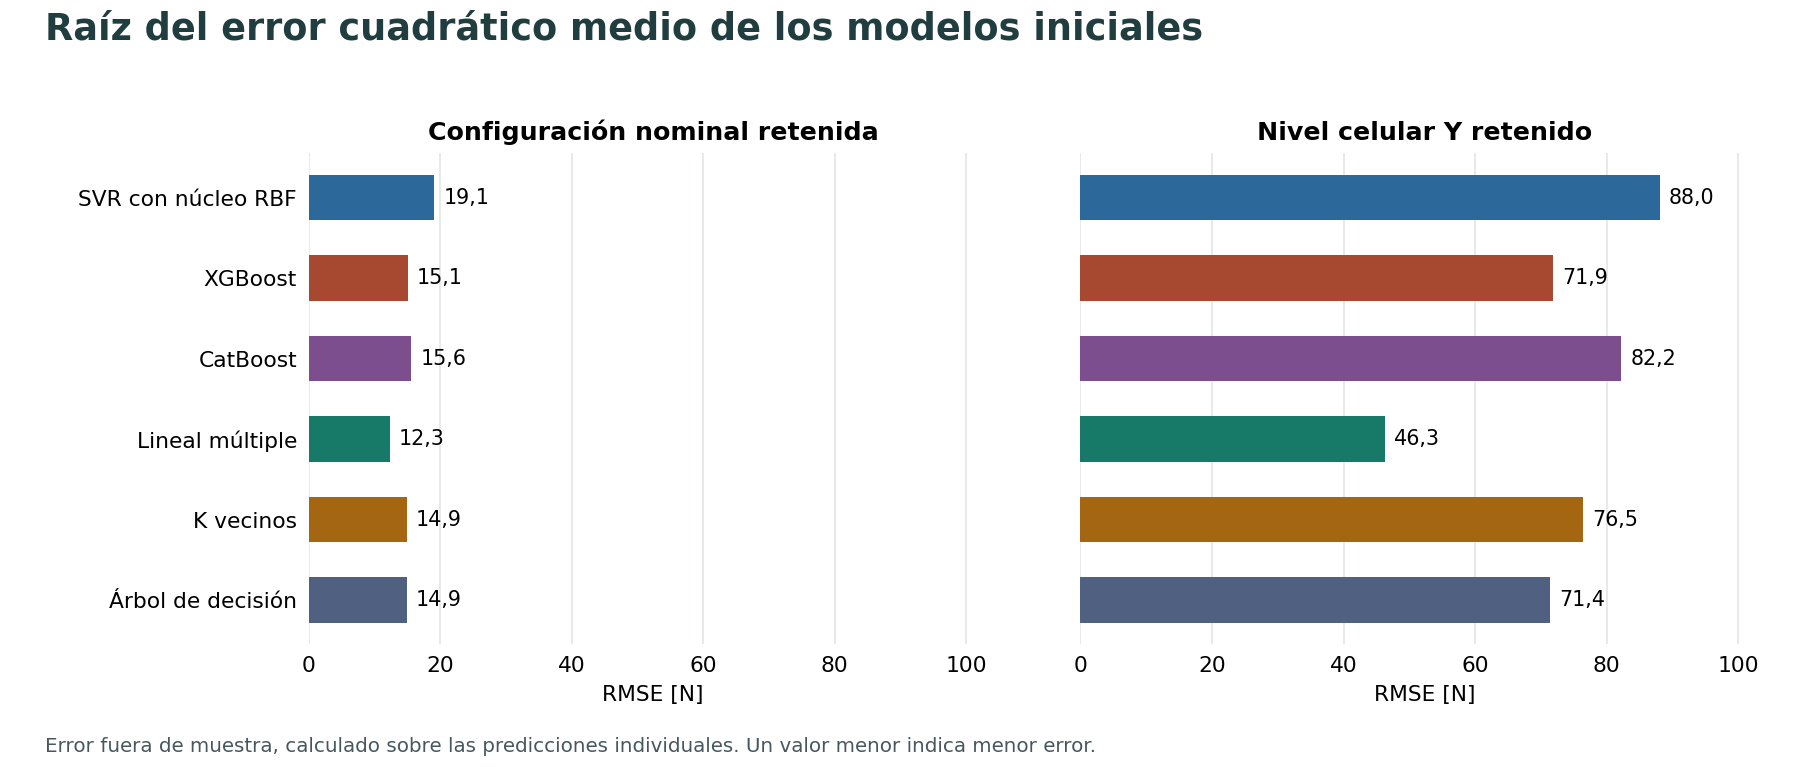

In [40]:
figura(3, _barras, "RMSE_N", 3)

In [41]:
mejor_rmse = principal.RMSE_N.idxmin()
gap_rmse = (principal.RMSE_N - principal.MAE_N).idxmax()
print(f"En configuración, {nombre(mejor)} alcanza el menor MAE ({fmt(principal.loc[mejor, 'MAE_N'])} N). "
      f"El menor RMSE corresponde a {nombre(mejor_rmse)} ({fmt(principal.loc[mejor_rmse, 'RMSE_N'])} N).")

En configuración, Lineal múltiple alcanza el menor MAE (9,66 N). El menor RMSE corresponde a Lineal múltiple (12,31 N).


### 4.3 Diagnóstico de errores

La brecha entre entrenamiento y validación ayuda a detectar sensibilidad a la geometría reservada. Los cuantiles muestran si los errores grandes se concentran en la cola de la distribución.

In [42]:
def _entrenamiento(data: dict) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    y = np.arange(len(MODELOS))
    for ax, proto in zip(axes, PROTOCOLOS):
        rows = (
            _filas(data["folds"], proto)
            .groupby("procedimiento")[["MAE_train_N", "MAE_validacion_N"]]
            .mean()
            .loc[list(MODELOS)]
        )
        ax.hlines(y, rows.MAE_train_N, rows.MAE_validacion_N, color="#AEBBC0", linewidth=1.5)
        ax.scatter(rows.MAE_train_N, y, color=AZUL, s=35, label="Entrenamiento", zorder=3)
        ax.scatter(
            rows.MAE_validacion_N,
            y,
            color=VERDE,
            marker="D",
            s=32,
            label="Validación externa",
            zorder=3,
        )
        ax.set(
            title=PROTO[proto],
            xlabel="MAE medio por pliegue [N]",
            yticks=y,
            yticklabels=[NOMBRES[m] for m in MODELOS],
            ylim=(5.6, -0.6),
        )
        _estilo(ax)
    axes[0].set_xlim(left=0)
    fig.legend(
        *axes[0].get_legend_handles_labels(),
        loc="lower center",
        bbox_to_anchor=(0.56, 0.08),
        ncol=2,
        frameon=False,
    )
    _encabezado(
        fig,
        4,
        "Cada pliegue pesa lo mismo en ambas series. La brecha también recoge el cambio en la geometría evaluada.",
    )
    fig.subplots_adjust(left=0.17, right=0.975, top=0.82, bottom=0.23, wspace=0.12)
    return fig

#### Figura 4. Error en entrenamiento y en validación externa

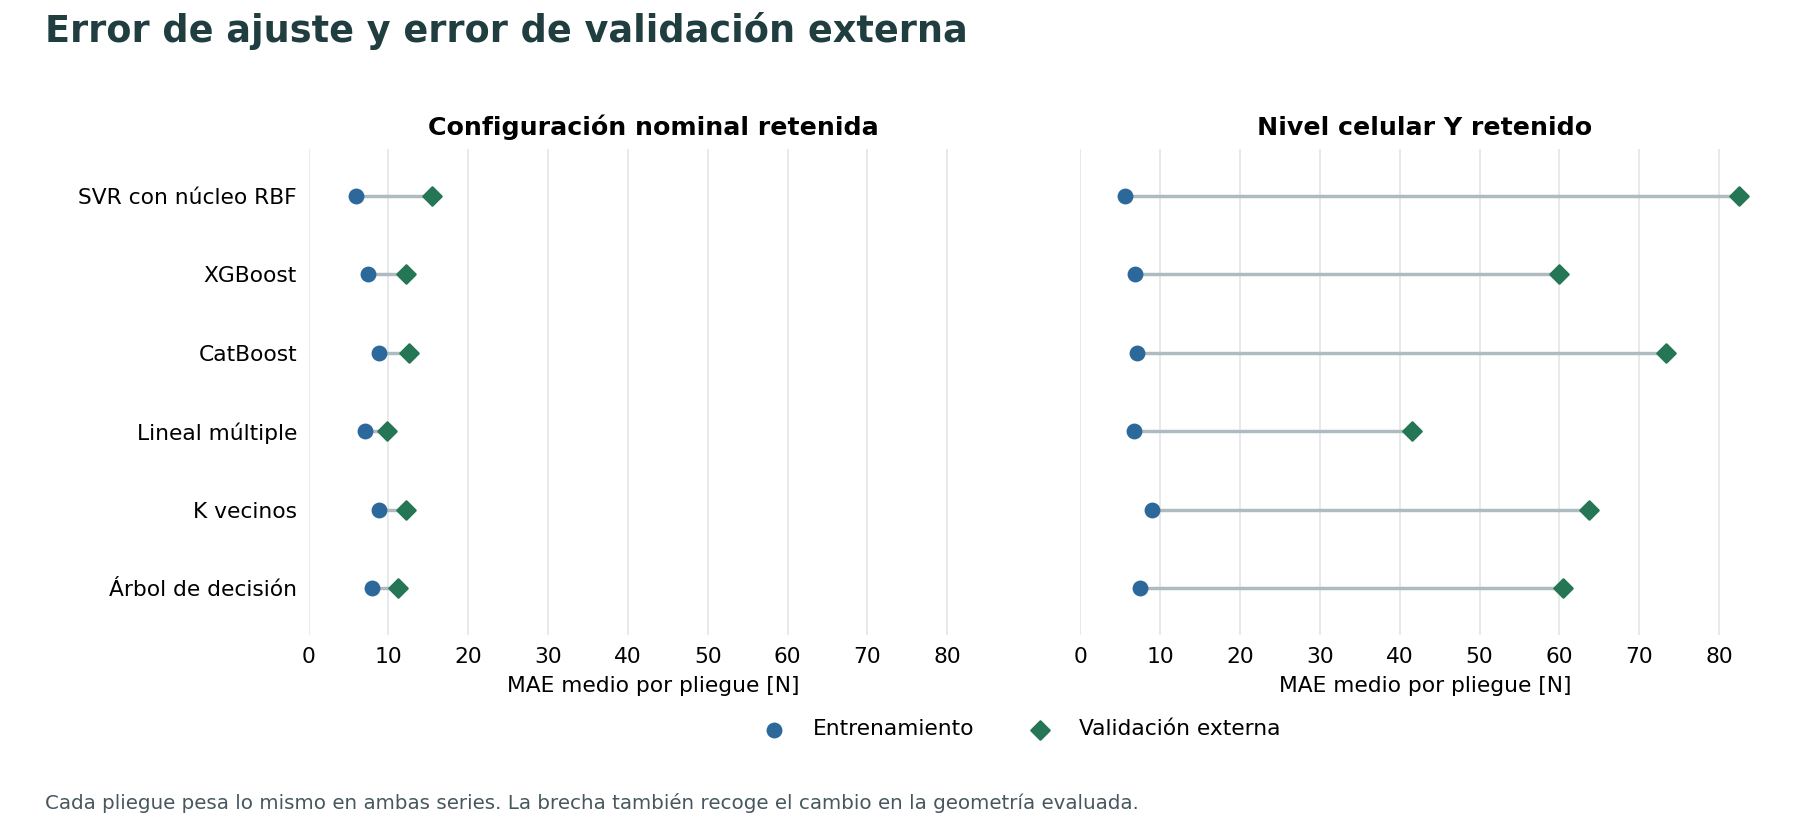

In [43]:
figura(4, _entrenamiento)

In [44]:
brecha = (folds[folds.procedimiento.isin(MODELOS)].assign(brecha_N=lambda x:x.MAE_validacion_N-x.MAE_train_N)
          .groupby(["protocolo","procedimiento"]).brecha_N.mean().unstack("protocolo"))
arboles = ["Arbol_decision","XGBoost","CatBoost"]
detalle("Brecha de error de los tres modelos de árboles [N]", brecha.loc[arboles].rename(index=nombre).rename_axis("Modelo").reset_index())
mayor_brecha = brecha.configuracion.idxmax()
print(f"{nombre(mayor_brecha)} muestra la mayor brecha media entre validación y entrenamiento "
      f"en configuraciones ({fmt(brecha.loc[mayor_brecha, 'configuracion'])} N).")

**Brecha de error de los tres modelos de árboles [N]**

| Modelo | configuracion | familia |
| :--- | ---: | ---: |
| Árbol de decisión | 3,246 | 52,981 |
| XGBoost | 4,720 | 53,129 |
| CatBoost | 3,720 | 66,261 |

SVR con núcleo RBF muestra la mayor brecha media entre validación y entrenamiento en configuraciones (9,55 N).


In [45]:
def _observado(data: dict) -> plt.Figure:
    rows = data["oof"].loc[data["oof"].procedimiento.isin(MODELOS)].copy()
    # Cuartiles de la carga medida para resumir la gráfica, después de la validación.
    por_probeta = rows.groupby("Case_n").observado_N
    if not por_probeta.nunique(dropna=False).eq(1).all():
        raise ValueError("La carga observada debe coincidir en todas las predicciones de cada probeta.")
    tramo_por_probeta = pd.qcut(por_probeta.first(), q=4, duplicates="drop")
    rows["tramo"] = rows.Case_n.map(tramo_por_probeta)
    curvas = (rows.groupby(["procedimiento", "protocolo", "tramo"], observed=True)
              [["observado_N", "predicho_N"]].mean().reset_index())
    fig, axes = plt.subplots(2, 3, figsize=(10.3, 7.1), sharex=True, sharey=True)
    extremos = curvas[["observado_N", "predicho_N"]].to_numpy()
    low, high = extremos.min(), extremos.max()
    pad = max(1, 0.05 * (high - low))
    for ax, m in zip(axes.flat, MODELOS):
        ax.plot([low-pad, high+pad], [low-pad, high+pad], "--", color=GRIS, lw=1)
        for p, marcador, color in zip(PROTOCOLOS, ("o", "s"), (AZUL, "#B0573A")):
            q = curvas.loc[(curvas.procedimiento == m) & (curvas.protocolo == p)]
            ax.plot(q.observado_N, q.predicho_N, marker=marcador, lw=1.4, color=color, label=PROTO[p])
        ax.set(title=NOMBRES[m], xlim=(low-pad, high+pad), ylim=(low-pad, high+pad), aspect="equal")
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.yaxis.set_major_locator(MaxNLocator(4))
        _estilo(ax, "both")
    fig.supxlabel("Carga observada media [N]", y=0.10, fontsize=10)
    fig.supylabel("Carga predicha media [N]", x=0.02, fontsize=10)
    fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="lower center",
               ncol=2, bbox_to_anchor=(0.53, 0.036), frameon=False)
    _encabezado(fig, 2, "Medias por cuartil de carga observada. La diagonal indica igualdad. MAE y RMSE se calculan con predicciones individuales.")
    fig.subplots_adjust(left=0.10, right=0.97, top=0.88, bottom=0.19, hspace=0.28, wspace=0.18)
    return fig

In [46]:
figura(2, _observado)
iniciales_oof = oof[oof.procedimiento.isin(MODELOS)].copy()
maximos = iniciales_oof.loc[iniciales_oof.groupby(["protocolo","procedimiento"]).error_absoluto_N.idxmax(),
                            ["protocolo","procedimiento","observado_N","predicho_N","error_absoluto_N"]]
detalle("Mayor error por modelo y protocolo", maximos)
peor_caso = maximos[maximos.protocolo.eq("configuracion")].nlargest(1,"error_absoluto_N").iloc[0]
print(f"Mayor error por configuración: {nombre(peor_caso.procedimiento)}, "
      f"Observado {fmt(peor_caso.observado_N)} N, predicho {fmt(peor_caso.predicho_N)} N.")

**Mayor error por modelo y protocolo**

| protocolo | procedimiento | observado_N | predicho_N | error_absoluto_N |
| :--- | :--- | ---: | ---: | ---: |
| configuracion | Arbol_decision | 47,550 | 98,086 | 50,536 |
| configuracion | CatBoost | 47,550 | 94,789 | 47,239 |
| configuracion | KNN | 208,740 | 179,807 | 28,933 |
| configuracion | Lineal_multiple | 47,550 | 77,831 | 30,281 |
| configuracion | SVR_RBF | 47,550 | 99,211 | 51,661 |
| configuracion | XGBoost | 47,550 | 94,693 | 47,143 |
| familia | Arbol_decision | 215,520 | 94,560 | 120,960 |
| familia | CatBoost | 215,520 | 94,486 | 121,034 |
| familia | KNN | 215,520 | 91,553 | 123,967 |
| familia | Lineal_multiple | 193,200 | 104,411 | 88,789 |
| familia | SVR_RBF | 215,520 | 88,384 | 127,136 |
| familia | XGBoost | 212,430 | 88,981 | 123,449 |

Mayor error por configuración: SVR con núcleo RBF, Observado 47,55 N, predicho 99,21 N.


In [47]:
def _distribucion(data: dict) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.9), sharex=True, sharey=True)
    for ax, proto in zip(axes, PROTOCOLOS):
        q = _filas(data["oof"], proto)
        for pos, m in enumerate(MODELOS):
            val = q[q.procedimiento.eq(m)].sort_values("Case_n").error_absoluto_N.to_numpy()
            p10, q25, median, q75, p90 = np.quantile(val, [0.10, 0.25, 0.50, 0.75, 0.90])
            ax.hlines(pos, p10, p90, color=COLORES[m], lw=1.2)
            ax.hlines(pos, q25, q75, color=COLORES[m], lw=5)
            ax.plot(median, pos, "|", markersize=13, markeredgewidth=2, color="#13282B")
        ax.set(
            title=PROTO[proto],
            xlabel="Error absoluto por espécimen [N]",
            yticks=np.arange(6),
            yticklabels=[NOMBRES[m] for m in MODELOS],
            ylim=(5.6, -0.6),
        )
        _estilo(ax)
    axes[0].set_xlim(left=0)
    _encabezado(
        fig,
        5,
        "Línea fina: percentiles 10 a 90. Segmento grueso: rango intercuartílico. Marca vertical: mediana.",
    )
    fig.subplots_adjust(left=0.17, right=0.975, top=0.82, bottom=0.17, wspace=0.12)
    return fig

#### Figura 5. Distribución de los errores absolutos

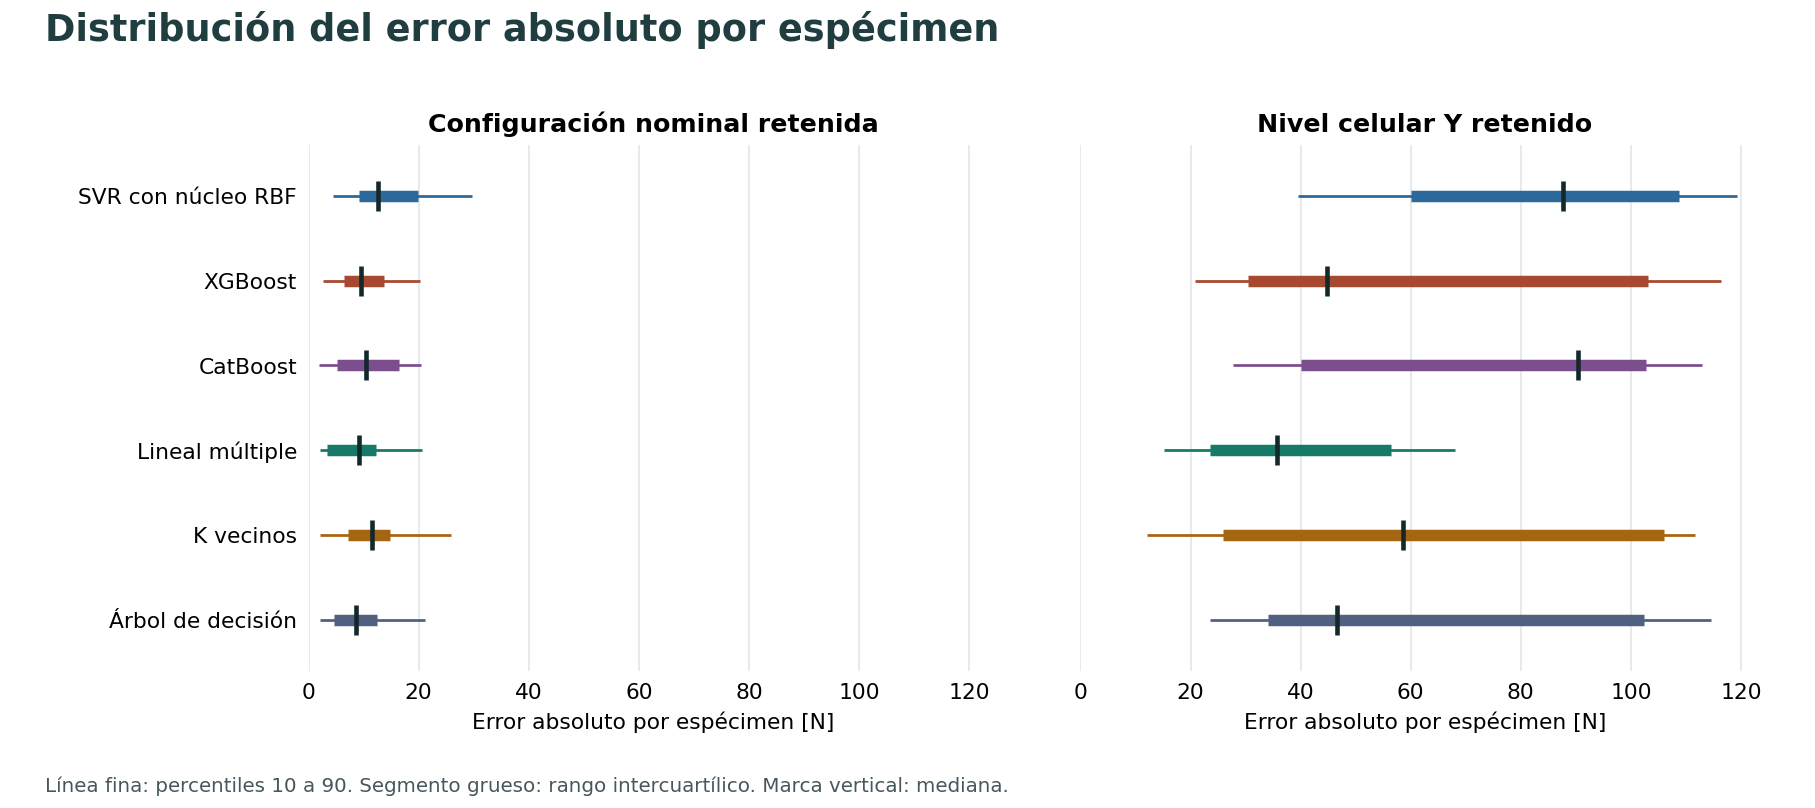

In [48]:
figura(5, _distribucion)

In [49]:
ultimos = principal.DE_error_absoluto_N.idxmax()
print(f"En configuraciones, {nombre(ultimos)} presenta la mayor desviación estándar de los errores absolutos "
      f"por probeta ({fmt(principal.loc[ultimos, 'DE_error_absoluto_N'])} N).")

En configuraciones, SVR con núcleo RBF presenta la mayor desviación estándar de los errores absolutos por probeta (11,16 N).


## 5. Ajuste de hiperparámetros mediante búsqueda aleatoria

### 5.1 Validación cruzada anidada por grupos

Primero se separa la reserva externa. **Dentro de su entrenamiento**, se crean los pliegues internos: `GroupKFold(n_splits=5)` para configuraciones nominales y `LeaveOneGroupOut` para niveles celulares. Cada configuración candidata se evalúa sobre predicciones internas fuera de muestra, con el preprocesamiento reajustado en cada entrenamiento interno. Se conserva la reserva externa hasta haber fijado familia y parámetros.

In [50]:
def inner_splits(frame, outer_train, protocol):
    """Devuelve índices relativos a outer_train; nunca observa el target."""
    subset = frame.iloc[np.asarray(outer_train, dtype=int)]
    if protocol == 'configuracion':
        grouping = nominal_groups(subset, GROUP_COLUMNS)
        if grouping.nunique() < 5:
            raise ValueError('Se requieren al menos cinco configuraciones en train externo.')
        splitter = GroupKFold(n_splits=5)
    elif protocol == 'familia':
        grouping = subset.n_cells_Y.astype(int).astype(str)
        if grouping.nunique() < 2:
            raise ValueError('Se requieren al menos dos familias en train externo.')
        splitter = LeaveOneGroupOut()
    else:
        raise ValueError(f'Protocolo no reconocido: {protocol}')
    result = list(splitter.split(subset, groups=grouping))
    seen = []
    for train, validation in result:
        if set(grouping.iloc[train]) & set(grouping.iloc[validation]):
            raise ValueError('Solapamiento de grupos internos.')
        if set(train) & set(validation) or set(train) | set(validation) != set(range(len(subset))):
            raise ValueError('Partición interna incompleta.')
        seen.extend(validation.tolist())
    if sorted(seen) != list(range(len(subset))):
        raise ValueError('Cada caso de train externo debe validarse internamente una vez.')
    return result

### 5.2 Cribado de familias

SVR, XGBoost, CatBoost, K vecinos y árbol de decisión se evalúan primero con su receta inicial. Para cada plaza se consideran las familias restantes a 1 N o menos del menor MAE interno. Dentro de esa banda, se prefiere la menor desviación absoluta mediana (MAD) de los MAE por grupo. Si persiste el empate, se usa el menor MAE y luego el orden de complejidad fijado. Pasan dos familias. Mínimos cuadrados permanece como referencia fija.

In [51]:
def inner_metrics(y: np.ndarray, pred: np.ndarray, groups: np.ndarray) -> tuple[float, float]:
    """MAE pooled por caso y MAD no escalada de las MAE por grupo."""
    errors = np.abs(np.asarray(y) - np.asarray(pred))
    means = pd.Series(errors).groupby(np.asarray(groups)).mean()
    return (float(errors.mean()), float(np.median(np.abs(means - np.median(means)))))


def rank_families(scores: dict[str, tuple[float, float]], cfg: Params) -> list[str]:
    """Ordena por banda de MAE, estabilidad interna y orden congelado."""
    remaining = dict(scores)
    order = []
    while remaining:
        limit = min((v[0] for v in remaining.values())) + cfg['banda_cribado_N']
        eligible = [f for f, v in remaining.items() if v[0] <= limit + 1e-12]
        chosen = min(eligible,
            key=lambda f: (remaining[f][1], remaining[f][0], cfg['orden_complejidad'].index(f), f))
        order.append(chosen)
        del remaining[chosen]
    return order

In [52]:
def registrar_reservas_internas(X, y, groups, splits, context, rows):
    if not X.index.equals(y.index) or len(groups) != len(X):
        raise ValueError('Índices internos incongruentes.')
    seen = []
    for s, (tr, va) in enumerate(splits, 1):
        if set(tr) & set(va) or set(groups[tr]) & set(groups[va]) or set(tr) | set(va) != set(range(len(X))):
            raise ValueError('Fuga en partición interna.')
        seen.extend(va)
        rows['particiones_internas'].append({**context, 'split': s, 'casos_train': _ids(X.index[tr]),
            'casos_validacion': _ids(X.index[va]), 'grupos_train': _object(sorted(set(groups[tr]))),
            'grupos_validacion': _object(sorted(set(groups[va])))})
    if sorted(seen) != list(range(len(X))):
        raise ValueError('Cobertura interna OOF incompleta.')

In [53]:
def evaluar_internamente(family, order, params, X, y, groups, splits, cfg, context, rows) -> tuple[tuple[float, float], float]:
    start = perf_counter()
    p = np.full(len(X), np.nan)
    cid = f'{family}_{order:02d}'
    for s, (tr, va) in enumerate(splits, 1):
        c = {**context, 'split': s, 'etapa_ajuste': 'cribado' if order == 0 else 'busqueda', 'config_id': cid}
        obj, _ = _fit(family, params, cfg, X.iloc[tr], y.iloc[tr], c, rows)
        p[va], _ = _predict(obj, X.iloc[va])
        for j in va:
            rows['predicciones_internas'].append({**c, 'familia_real': family, 'Case_n': int(X.index[j]),
                'grupo_interno': groups[j], 'observado_N': float(y.iloc[j]), 'predicho_N': float(p[j])})
    return (inner_metrics(y.to_numpy(), p, groups), perf_counter() - start)

In [54]:
def cribar_entrenamiento(X, y, groups, splits, cfg, context, rows):
    started = perf_counter()
    registrar_reservas_internas(X, y, groups, splits, context, rows)
    familias = [f for f in INITIAL if f in cfg["espacios"]]
    screen = {f: evaluar_internamente(f, 0, cfg["parametros_iniciales"][f],
              X, y, groups, splits, cfg, context, rows) for f in familias}
    ranking = rank_families({f: v[0] for f, v in screen.items()}, cfg)
    shortlisted = ranking[:cfg['numero_familias_tuning']]
    for rank, f in enumerate(ranking, 1):
        (mae, mad), secs = screen[f]
        rows['cribado_interno'].append({**context, 'familia_real': f, 'MAE_interno_N': mae,
            'MAD_grupos_N': mad, 'rango_cribado': rank, 'elegible_tuning': True,
            'seleccionada_tuning': f in shortlisted, 'tiempo_s': secs})
    return screen, shortlisted, perf_counter() - started

In [55]:
def datos_internos(tr, protocolo):
    grupos = nominal[tr] if protocolo == "configuracion" else X.iloc[tr].n_cells_Y.to_numpy()
    return X.iloc[tr], y.iloc[tr], grupos, inner_splits(frame, tr, protocolo)

cribados = {}
with threadpool_limits(limits=1):
    for protocolo, reservas in splits.items():
        for fold, (tr, _) in enumerate(reservas, 1):
            ctx = {"protocolo": protocolo, "fold": fold}
            cribados[protocolo, fold] = cribar_entrenamiento(
                *datos_internos(tr, protocolo), cfg, ctx, rows
            )
cribado = pd.DataFrame(rows["cribado_interno"])
seleccion = cribado.loc[cribado.seleccionada_tuning].copy()
conteos = seleccion[seleccion.protocolo.eq("configuracion")].familia_real.value_counts()
resultado["seleccion"] = seleccion

In [56]:
familias_cribadas = (seleccion.groupby("protocolo").familia_real
                     .agg(lambda serie: ", ".join(nombre(m) for m in sorted(serie.unique()))))
tabla(familias_cribadas.rename(index=PROTO).rename_axis("Protocolo")
      .reset_index(name="Familias que pasaron al ajuste"))

| Protocolo | Familias que pasaron al ajuste |
| :--- | :--- |
| Configuración nominal retenida | Árbol de decisión, CatBoost, K vecinos, XGBoost |
| Nivel celular Y retenido | CatBoost, K vecinos, SVR con núcleo RBF |

In [57]:
def _familias_residuos(data: dict) -> list[str]:
    """Primero el menor MAE inicial y después dos familias frecuentes en el cribado."""
    q = data["seleccion"]
    counts = q[q.protocolo.eq("configuracion")].familia_real.value_counts()
    fixed = _filas(data["metricas"], "configuracion").set_index("procedimiento")
    best = fixed.loc[list(MODELOS), "MAE_N"].idxmin()
    frequent = sorted(counts.index, key=lambda m: (-counts[m], MODELOS.index(m)))
    return [best, *[m for m in frequent if m != best][:2]]


def _residuos(data: dict) -> plt.Figure:
    familias = _familias_residuos(data)
    n = len(familias)
    fig, axes = plt.subplots(
        1, n, figsize=(4 * n + 0.8, 4.6), sharex=True, sharey=True, squeeze=False
    )
    for ax, m in zip(axes.flat, familias):
        for proto, marker, col in zip(PROTOCOLOS, ("o", "x"), (AZUL, "#B0573A")):
            q = _filas(data["oof"], proto, (m,))
            # Los cortes coincidentes se fusionan; si la predicción es constante se presenta su resumen.
            pred = q.predicho_N
            tramo = (pd.qcut(pred, q=4, duplicates="drop")
                     if pred.nunique() > 1 else pd.Series("constante", index=q.index))
            resumen = (q.assign(tramo=tramo, residuo=q.observado_N - pred)
                       .groupby("tramo", observed=True)
                       .agg(x=("predicho_N", "median"), y=("residuo", "median"),
                            inf=("residuo", lambda r: r.quantile(.25)),
                            sup=("residuo", lambda r: r.quantile(.75))))
            ax.vlines(resumen.x, resumen.inf, resumen.sup, color=col, alpha=.55, lw=1.8)
            ax.plot(resumen.x, resumen.y, marker=marker, color=col, label=PROTO[proto], lw=1.3)
        ax.axhline(0, color="#738489", ls="--", lw=1)
        ax.set(title=NOMBRES[m], xlabel="Predicción inicial [N]")
        _estilo(ax, "both")
    axes.flat[0].set_ylabel("Observación − predicción [N]")
    fig.legend(
        *axes.flat[0].get_legend_handles_labels(),
        loc="lower center",
        bbox_to_anchor=(0.54, 0.065),
        ncol=2,
        frameon=False,
    )
    _encabezado(
        fig,
        6,
        "Marcas: mediana por tramo de predicción. Barras: rango intercuartílico de los residuos. Un residuo positivo indica subestimación.",
    )
    fig.subplots_adjust(left=0.095, right=0.97, top=0.81, bottom=0.23, wspace=0.15)
    return fig

#### Figura 6. Sesgo y dispersión de los residuos

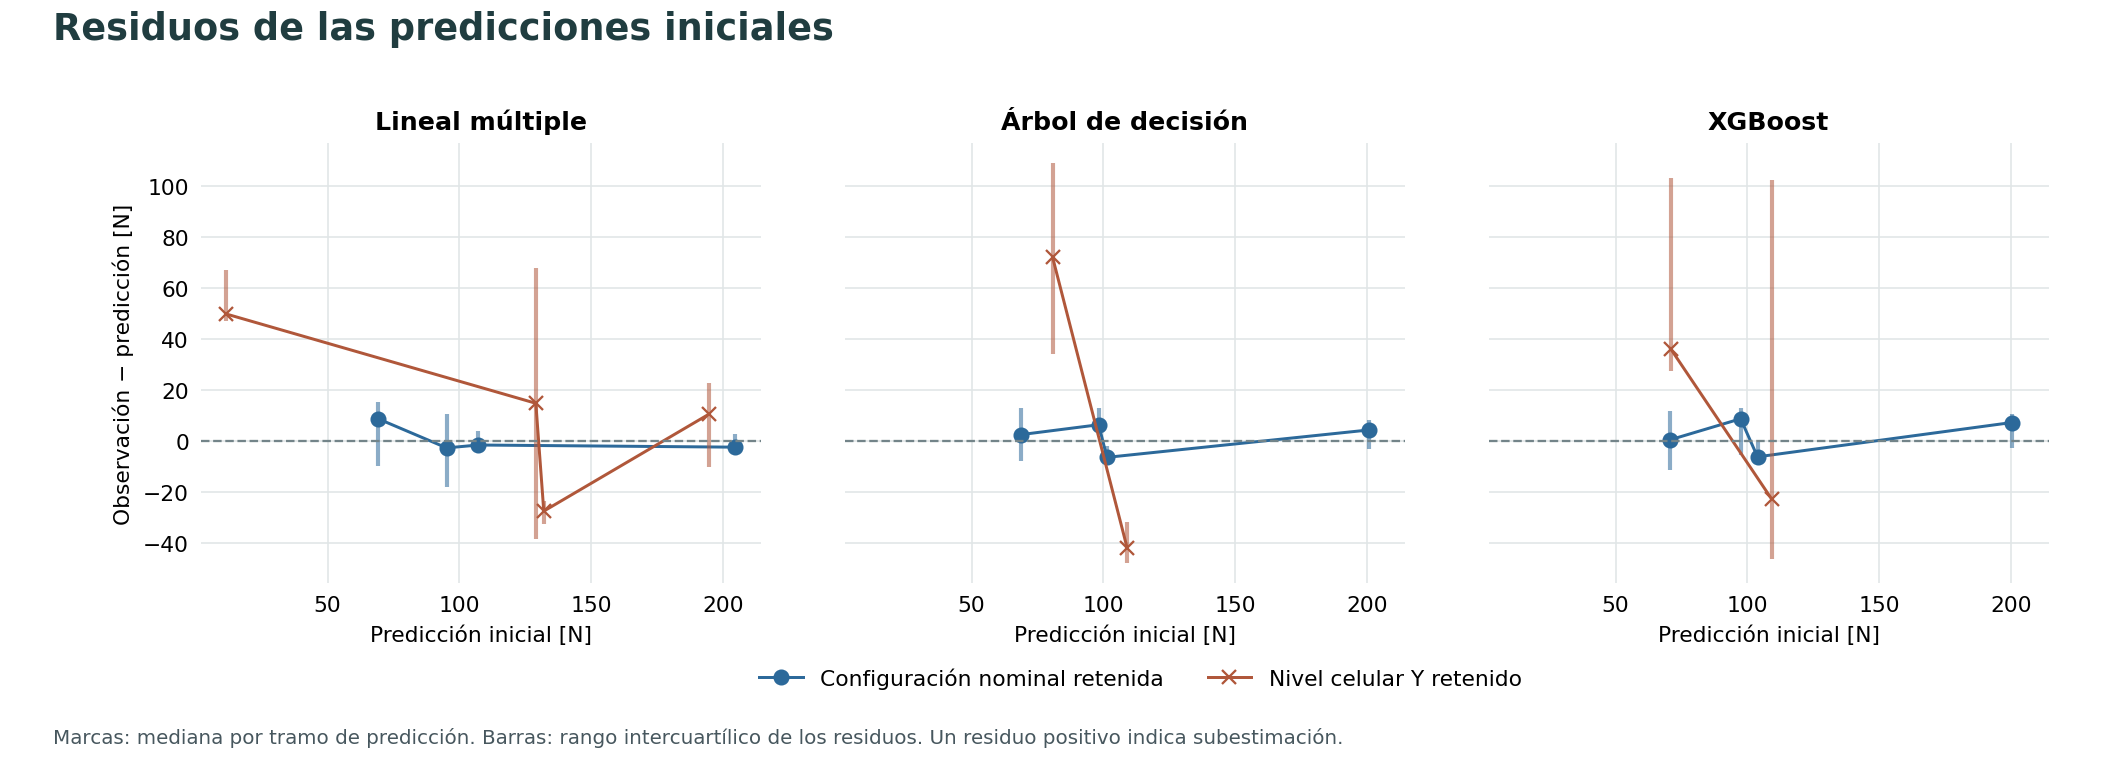

In [58]:
figura(6, _residuos)

In [59]:
conteos = seleccion[seleccion.protocolo.eq("configuracion")].familia_real.value_counts()
sv = principal.loc["SVR_RBF"]
print(f"Para SVR, el sesgo medio por configuración es {fmt(sv.sesgo_N)} N. En el gráfico el residuo sigue "
      "la convención observación menos predicción.")

Para SVR, el sesgo medio por configuración es -1,24 N. En el gráfico el residuo sigue la convención observación menos predicción.


### 5.3 Espacio discreto y presupuesto de búsqueda

**Se empleó búsqueda aleatoria uniforme sin reemplazo.** Python construye el producto cartesiano de los valores permitidos por hiperparámetro. La configuración inicial siempre entra; NumPy sortea siete combinaciones distintas del resto (`Generator.choice(..., replace=False)`). El plan de ocho recetas por familia usa la semilla base **20261106** más su índice en el listado de modelos y se reutiliza entre reservas. El sorteo solo depende del espacio y la semilla.

In [60]:
orden_parametros = {
    "SVR_RBF": ("C", "epsilon", "gamma"),
    "XGBoost": ("max_depth", "n_estimators", "learning_rate", "min_child_weight", "reg_lambda"),
    "CatBoost": ("iterations", "depth", "learning_rate", "l2_leaf_reg"),
    "KNN": ("n_neighbors", "weights", "p"),
    "Arbol_decision": ("max_depth", "min_samples_leaf"),
}
assert all(set(orden_parametros[f]) == set(cfg["espacios"][f]) for f in orden_parametros)


def freeze_candidates(cfg: Params) -> dict[str, list[Params]]:
    """Muestrea una vez cada pequeño espacio, sin y, folds ni resultados."""
    result = {}
    for i, family in enumerate(INITIAL):
        if family not in cfg['espacios']:
            continue
        fixed = cfg['parametros_iniciales'][family]
        space = cfg['espacios'][family]
        keys = list(orden_parametros[family])
        pool = [dict(fixed, **dict(zip(keys, row))) for row in product(*(space[k] for k in keys))]
        pool = [p for p in pool if p != fixed]
        rng = np.random.default_rng(cfg['semilla'] + i)
        inds = rng.choice(len(pool), size=cfg['presupuesto_por_candidata'] - 1, replace=False)
        result[family] = [fixed.copy(), *[pool[j] for j in inds]]
    return result

draws = freeze_candidates(cfg)  # Usa solo la semilla y el espacio publicados en la configuración.
assert len(draws) == 5 and all(len(candidates) == 8 for candidates in draws.values())

In [61]:
tabla(pd.DataFrame([
    {"Modelo": nombre(familia), "Espacio discreto": json.dumps(espacio, ensure_ascii=False),
     "Configuraciones por búsqueda": len(draws[familia])}
    for familia, espacio in cfg["espacios"].items()
]))
presupuesto = cfg["presupuesto_por_candidata"]
print(f"{presupuesto} recetas por candidata · semilla {cfg['semilla']}.")

| Modelo | Espacio discreto | Configuraciones por búsqueda |
| :--- | :--- | ---: |
| SVR con núcleo RBF | {"C": [25, 100, 250], "epsilon": [2, 5, 10], "gamma": ["scale", 0.03, 0.3]} | 8 |
| XGBoost | {"max_depth": [1, 2, 3], "n_estimators": [40, 60, 80], "learning_rate": [0.03, 0.075, 0.15], "min_child_weight": [1, 2, 4], "reg_lambda": [1, 3, 10]} | 8 |
| CatBoost | {"iterations": [40, 60, 80], "depth": [1, 2, 3], "learning_rate": [0.03, 0.075, 0.15], "l2_leaf_reg": [2, 5, 12]} | 8 |
| K vecinos | {"n_neighbors": [2, 3, 4, 5, 7], "weights": ["uniform", "distance"], "p": [1, 2]} | 8 |
| Árbol de decisión | {"max_depth": [1, 2, 3], "min_samples_leaf": [2, 3, 4]} | 8 |

8 recetas por candidata · semilla 20261106.


### 5.4 Elección de parámetros y evaluación externa

Para cada candidata gana la receta con el menor MAE interno por probeta. Una diferencia dentro de `1e−10` N se trata como empate numérico: se prefiere menor MAD entre grupos y después el orden del sorteo. Entre las dos ganadoras se aplica el mismo criterio, con el orden de cribado como último desempate. Se reajusta la receta elegida sobre todo el entrenamiento externo antes de predecir la reserva.

In [62]:
def best_index(losses: list[tuple[float, float]]) -> int:
    """Menor MAE; empate numérico por MAD y orden del plan."""
    minimum = min((x[0] for x in losses))
    return min((i for i, v in enumerate(losses) if v[0] <= minimum + 1e-10), key=lambda i: (losses[i][1], i))

In [63]:
def afinar(X, y, groups, splits, cfg, draws, context, rows, cribado_previo):
    screen, shortlisted, seconds_screen = cribado_previo
    started = perf_counter()
    winners = []
    for rank, f in enumerate(shortlisted, 1):
        values = [screen[f]] + [evaluar_internamente(f, i, draws[f][i], X, y, groups, splits, cfg, context, rows) for i in range(1, len(draws[f]))]
        idx = best_index([s for s, _ in values])
        best = np.inf
        for i, ((mae, mad), secs) in enumerate(values):
            best = min(mae, best)
            rows['busqueda_interna'].append({**context, 'familia_real': f, 'orden': i + 1,
                'config_id': f'{f}_{i:02d}', 'parametros_json': _object(draws[f][i]), 'MAE_interno_N': mae,
                'MAD_grupos_N': mad, 'mejor_acumulado_N': best, 'seleccionada': i == idx,
                'tiempo_s': secs if i else 0.0, 'reuso_cribado': i == 0})
        (mae, mad), _ = values[idx]
        winners.append({'rango_cribado': rank, 'familia_real': f, 'config_id': f'{f}_{idx:02d}',
            'parametros': draws[f][idx], 'MAE_interno_N': mae, 'MAD_grupos_N': mad})
    chosen = best_index([(w['MAE_interno_N'], w['MAD_grupos_N']) for w in winners])
    for i, w in enumerate(winners):
        rows['seleccion_tuning'].append({**context, **{k: v for k, v in w.items() if k != 'parametros'},
            'parametros_json': _object(w['parametros']), 'elegida_selector': i == chosen})
    return (winners, chosen, seconds_screen + perf_counter() - started)

In [64]:
with threadpool_limits(limits=1):
    for protocol, outer in splits.items():
        for fold, (tr, te) in enumerate(outer, 1):
            ctx = {'protocolo': protocol, 'fold': fold}
            inner = inner_splits(frame, tr, protocol)
            grouping = nominal[tr] if protocol == 'configuracion' else X.iloc[tr].n_cells_Y.to_numpy()
            winners, chosen, search_s = afinar(X.iloc[tr], y.iloc[tr], grouping, inner, cfg, draws, ctx,
                rows, cribados[protocol, fold])
            for i, w in enumerate(winners):
                proc = ADAPT[i]
                f = w['familia_real']
                obj, fit_s = _fit(f, w['parametros'], cfg, X.iloc[tr], y.iloc[tr],
                    {**ctx, 'etapa_ajuste': 'externa_optimizada', 'config_id': w['config_id']}, rows)
                pred, pred_s = _predict(obj, X.iloc[te])
                pt, _ = _predict(obj, X.iloc[tr])
                initial = cache[protocol, fold, f]
                _record(proc, f, ctx, X, y, tr, te, nominal, pred, pt, fit_s, pred_s, search_s, initial, rows)
                ajustes_para_diagnostico.append((obj, f, tr, te, {**ctx, 'procedimiento': proc}))
                if i == chosen:
                    _record(ADAPT[2], f, ctx, X, y, tr, te, nominal, pred, pt, fit_s, pred_s, search_s, initial, rows)

### 5.5 Reajuste para uso posterior

Se repite el procedimiento sobre la campaña completa para obtener una receta aplicable a nuevos ensayos. Los errores externos corresponden al procedimiento anidado. La receta reajustada requiere una prueba experimental posterior.

In [65]:
tr = np.arange(len(X))
ctx = {"protocolo":"campana_completa", "fold":0}
modelos_campana = {}
with threadpool_limits(limits=1):
    internos = inner_splits(frame, tr, "configuracion")
    elegibles = cribar_entrenamiento(X, y, nominal, internos, cfg, ctx, rows)
    winners, chosen, _ = afinar(X, y, nominal, internos, cfg, draws, ctx, rows, elegibles)
    for w in winners:
        f = w["familia_real"]
        modelos_campana[f], _ = _fit(
            f, w["parametros"], cfg, X, y,
            {**ctx,"etapa_ajuste":"reajuste_campana","config_id":w["config_id"]}, rows)
receta = {
    "protocolo":"configuracion", "casos_train":X.index.tolist(), "feature_set":"A",
    "alcance":"Reajuste con todos los especímenes observados; sin evaluación externa nueva.",
    "candidatas":winners, "selector":winners[chosen],
}

In [66]:
rows["metricas_resumen"].clear()
_summarize(rows)
frames = {nombre_tabla: pd.DataFrame(filas) for nombre_tabla, filas in rows.items()}
resultado = {
    "metricas": frames["metricas_resumen"], "oof": frames["predicciones_oof"],
    "folds": frames["metricas_folds"], "busqueda": frames["busqueda_interna"],
    "cribado": frames["cribado_interno"], "seleccion": frames["seleccion_tuning"],
}
metricas, oof, folds = (resultado[k] for k in ("metricas","oof","folds"))
busqueda, seleccion, cribado = (
    resultado[k].loc[resultado[k].protocolo.isin(PROTOCOLOS)].copy()
    for k in ("busqueda", "seleccion", "cribado")
)
assert busqueda.groupby(["protocolo", "fold", "familia_real"]).size().eq(presupuesto).all()
assert len(oof) == len(X) * len(PROTOCOLOS) * (len(INITIAL) + len(REFS) + len(ADAPT))
assert not oof.duplicated(["protocolo", "procedimiento", "Case_n"]).any()
duracion_motor_s = perf_counter() - started

In [67]:
def _busqueda(data: dict) -> plt.Figure:
    trace = data["busqueda"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    for ax, proto in zip(axes, PROTOCOLOS):
        q = trace[trace.protocolo.eq(proto)].sort_values("orden").copy()
        first = q.groupby(["familia_real", "fold"]).mejor_acumulado_N.transform("first")
        q["mejora_N"] = first - q.mejor_acumulado_N
        for m, rows in q.groupby("familia_real"):
            cuantiles = rows.groupby("orden").mejora_N.quantile([0.25, 0.50, 0.75]).unstack()
            ax.fill_between(cuantiles.index, cuantiles[0.25], cuantiles[0.75], color=COLORES[m], alpha=.18)
            ax.plot(cuantiles.index, cuantiles[0.50], color=COLORES[m], label=NOMBRES[m], lw=2.6)
        ax.set(title=PROTO[proto], xlabel="Configuraciones internas evaluadas [orden]")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
        _estilo(ax, "both")
    axes[0].set_ylabel("Reducción acumulada del MAE interno [N]")
    axes[0].margins(y=0.08)
    legend = [
        Line2D([0], [0], color=COLORES[m], lw=2.5, label=NOMBRES[m])
        for m in MODELOS
        if m in set(trace.loc[trace.protocolo.isin(PROTOCOLOS), "familia_real"])
    ]
    fig.legend(
        handles=legend,
        loc="lower center",
        bbox_to_anchor=(0.54, 0.07),
        ncol=len(legend),
        fontsize=8.5,
        frameon=False,
    )
    _encabezado(
        fig,
        7,
        "Reducción frente a la configuración inicial. Línea: mediana por familia. Banda: rango intercuartílico entre entrenamientos.",
    )
    fig.subplots_adjust(left=0.09, right=0.98, top=0.80, bottom=0.24, wspace=0.13)
    return fig

#### Figura 7. Evolución de la búsqueda aleatoria

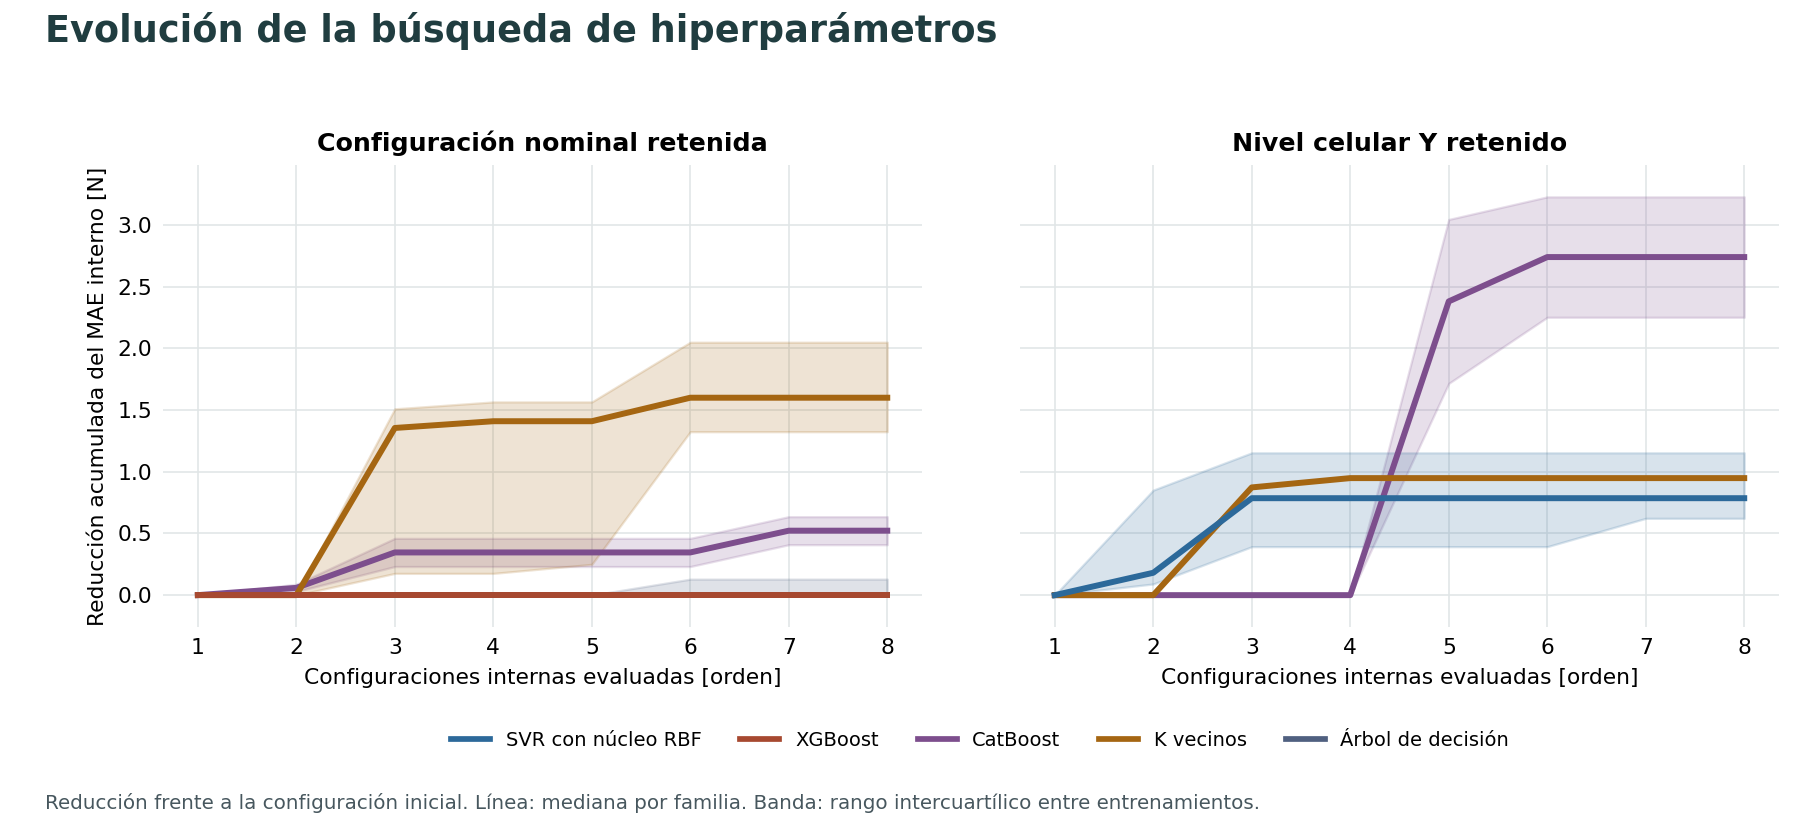

In [68]:
figura(7, _busqueda)

In [69]:
familias_elegidas = (seleccion.loc[seleccion.elegida_selector].groupby("protocolo").familia_real
                     .agg(lambda serie: ", ".join(nombre(m) for m in sorted(serie.unique()))))
tabla(familias_elegidas.rename(index=PROTO).rename_axis("Protocolo")
      .reset_index(name="Familias elegidas por la validación interna"))
final = receta["selector"]
ajustables = {k: final["parametros"][k] for k in cfg["espacios"][final["familia_real"]]}
print(f"Reajuste con la campaña completa: {nombre(final['familia_real'])}, {ajustables}.")

| Protocolo | Familias elegidas por la validación interna |
| :--- | :--- |
| Configuración nominal retenida | Árbol de decisión, CatBoost, K vecinos, XGBoost |
| Nivel celular Y retenido | SVR con núcleo RBF |

Reajuste con la campaña completa: Árbol de decisión, {'max_depth': 2, 'min_samples_leaf': 2}.


## 6. Comparación final y decisión

El efecto del tuning se mide sobre la misma probeta y la misma familia, antes y después del ajuste. La familia puede cambiar entre reservas. El tiempo de búsqueda es compartido por los procedimientos ajustados.

### 6.1 Errores emparejados y estabilidad

La diferencia frente a Ridge se calcula sobre una misma probeta. Para el efecto del tuning se compara la familia elegida en cada reserva con sus propios parámetros iniciales.

In [70]:
def _diferencias(data: dict) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    for ax, proto in zip(axes, PROTOCOLOS):
        q = data["oof"][data["oof"].protocolo.eq(proto)].pivot(
            index="Case_n", columns="procedimiento", values="error_absoluto_N"
        )
        for i, m in enumerate(MODELOS):
            delta = q[m] - q.Ridge_historico
            a, b = delta.quantile([0.25, 0.75])
            ax.hlines(i, a, b, color=COLORES[m], lw=4)
            ax.scatter(
                delta.mean(),
                i,
                marker="D",
                s=31,
                color=COLORES[m],
                edgecolor="white",
                lw=0.5,
                zorder=3,
            )
        ax.axvline(0, color="#738489", lw=1, ls="--")
        ax.set(
            title=PROTO[proto],
            xlabel="Diferencia de error absoluto [N]",
            yticks=np.arange(6),
            yticklabels=[NOMBRES[m] for m in MODELOS],
            ylim=(5.6, -0.6),
        )
        _estilo(ax)
    _encabezado(
        fig,
        8,
        "Rombo = media de diferencias pareadas, igual a ΔMAE. Segmento = cuartiles 1 y 3 por espécimen. Un valor negativo favorece al modelo.",
    )
    fig.subplots_adjust(left=0.17, right=0.975, top=0.82, bottom=0.17, wspace=0.12)
    return fig

#### Figura 8. Diferencia de error frente a Ridge

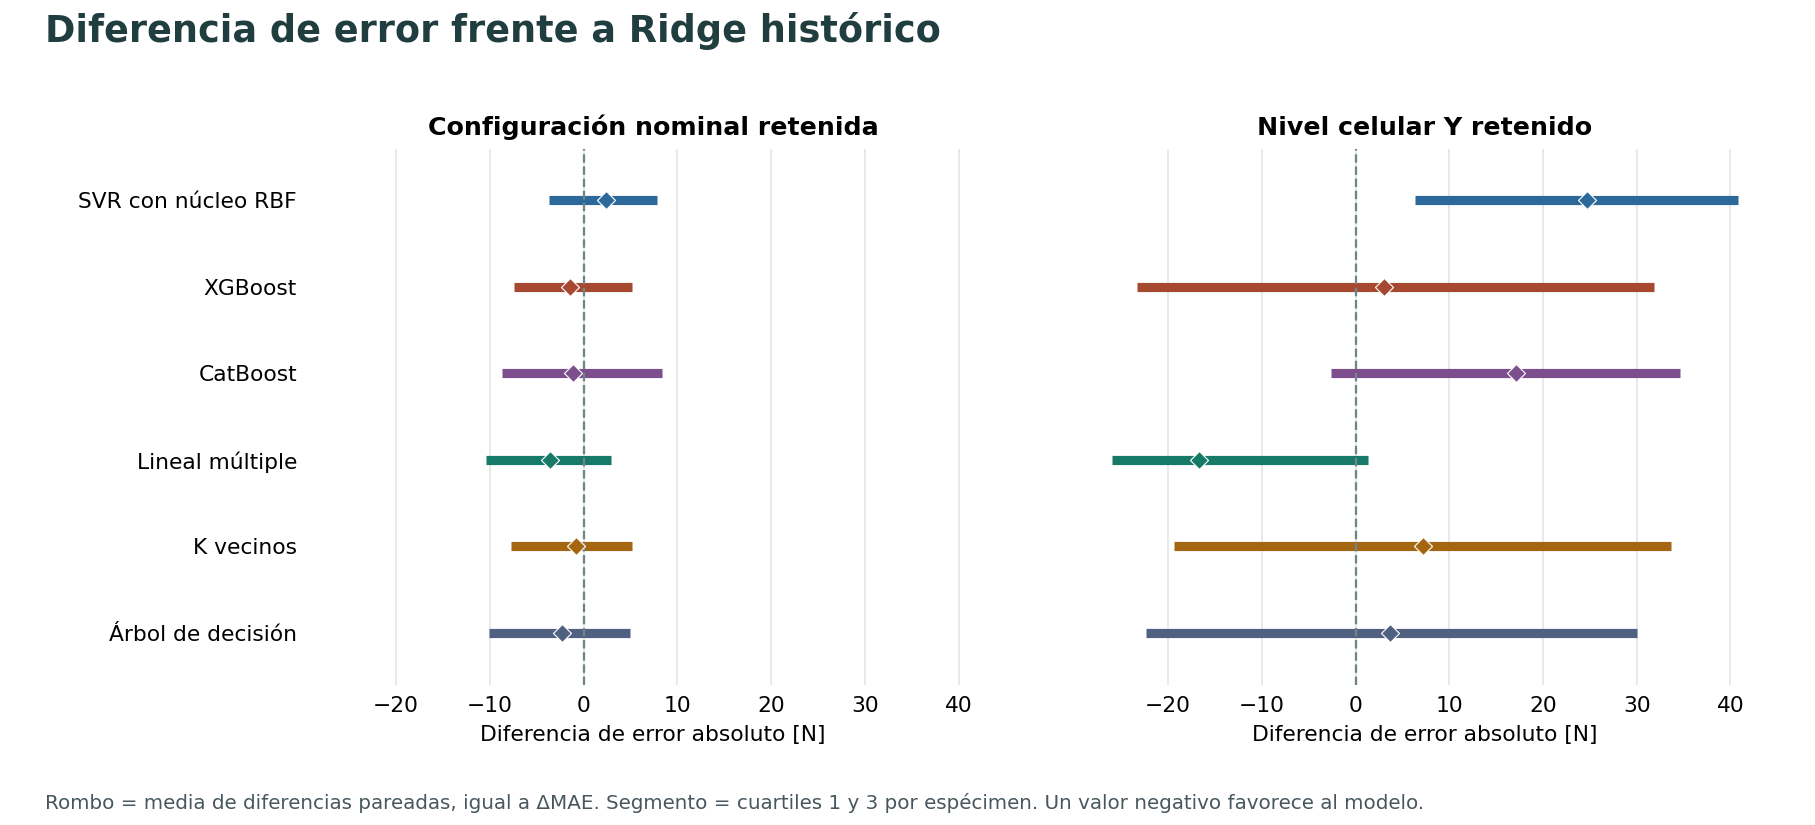

In [71]:
figura(8, _diferencias)

In [72]:
# El detalle de los dos puestos conserva la familia que realmente se seleccionó en cada reserva.
for p in PROTOCOLOS:
    t = resumen(p, [*REFS, *MODELOS, *ADAPT]).reset_index()
    t["Modelo"] = t.procedimiento.map(nombre)
    t["ΔMAE vs Ridge [N]"] = t.delta_MAE_vs_Ridge_N
    detalle(f"{PROTO[p]} · tabla integrada, controles y dos puestos del cribado",
            t[["Modelo", "MAE_N", "RMSE_N", "MedAE_N", "R2_OOF", "ΔMAE vs Ridge [N]",
               "DE_MAE_fold_N", "tiempo_ajuste_s", "tiempo_prediccion_s", "tiempo_busqueda_s"]])

diferencias = principal.delta_MAE_vs_Ridge_N.sort_values()
print(f"{nombre(diferencias.index[0])} reduce el MAE frente a Ridge en {fmt(-diferencias.iloc[0])} N "
      "al reservar configuraciones.")

**Configuración nominal retenida · tabla integrada, controles y dos puestos del cribado**

| Modelo | MAE_N | RMSE_N | MedAE_N | R2_OOF | ΔMAE vs Ridge [N] | DE_MAE_fold_N | tiempo_ajuste_s | tiempo_prediccion_s | tiempo_busqueda_s |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Mediana de entrenamiento | 49,748 | 64,699 | 35,890 | -0,213 | 36,502 | 41,054 | 0,016 | 0,006 | 0,000 |
| Media por nivel Y | 10,126 | 12,308 | 8,688 | 0,956 | -3,121 | 7,041 | 0,018 | 0,012 | 0,000 |
| Ridge histórico | 13,247 | 16,346 | 11,941 | 0,923 | 0,000 | 9,677 | 0,070 | 0,024 | 0,000 |
| SVR con núcleo RBF | 15,651 | 19,096 | 12,633 | 0,894 | 2,404 | 11,120 | 0,168 | 0,068 | 0,000 |
| XGBoost | 11,754 | 15,093 | 9,594 | 0,934 | -1,493 | 9,947 | 0,419 | 0,078 | 0,000 |
| CatBoost | 12,148 | 15,596 | 10,508 | 0,930 | -1,098 | 10,243 | 0,874 | 0,106 | 0,000 |
| Lineal múltiple | 9,664 | 12,308 | 9,136 | 0,956 | -3,583 | 7,905 | 0,179 | 0,072 | 0,000 |
| K vecinos | 12,429 | 14,923 | 11,515 | 0,935 | -0,818 | 8,104 | 0,156 | 1,801 | 0,000 |
| Árbol de decisión | 10,956 | 14,892 | 8,580 | 0,936 | -2,291 | 10,637 | 0,148 | 0,064 | 0,000 |
| Primera del cribado | 11,263 | 14,643 | 8,757 | 0,938 | -1,984 | 9,825 | 0,187 | 0,067 | 30,765 |
| Segunda del cribado | 13,749 | 18,852 | 9,704 | 0,897 | 0,502 | 12,558 | 0,257 | 0,073 | 30,765 |
| Selector interno | 12,998 | 17,180 | 9,336 | 0,914 | -0,248 | 10,519 | 0,190 | 0,068 | 30,765 |

**Nivel celular Y retenido · tabla integrada, controles y dos puestos del cribado**

| Modelo | MAE_N | RMSE_N | MedAE_N | R2_OOF | ΔMAE vs Ridge [N] | DE_MAE_fold_N | tiempo_ajuste_s | tiempo_prediccion_s | tiempo_busqueda_s |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Mediana de entrenamiento | 97,511 | 99,009 | 96,377 | -1,840 | 39,874 | 16,229 | 0,002 | 0,001 | 0,000 |
| Media por nivel Y | 80,593 | 87,521 | 84,392 | -1,219 | 22,955 | 38,870 | 0,002 | 0,001 | 0,000 |
| Ridge histórico | 57,637 | 60,428 | 64,520 | -0,058 | 0,000 | 17,145 | 0,009 | 0,003 | 0,000 |
| SVR con núcleo RBF | 82,358 | 88,039 | 87,602 | -1,246 | 24,720 | 33,871 | 0,019 | 0,008 | 0,000 |
| XGBoost | 60,684 | 71,889 | 44,810 | -0,497 | 3,046 | 44,640 | 0,034 | 0,009 | 0,000 |
| CatBoost | 74,726 | 82,248 | 90,312 | -0,960 | 17,089 | 34,093 | 0,087 | 0,011 | 0,000 |
| Lineal múltiple | 40,915 | 46,337 | 35,745 | 0,378 | -16,723 | 13,564 | 0,020 | 0,008 | 0,000 |
| K vecinos | 64,849 | 76,459 | 58,655 | -0,694 | 7,211 | 41,243 | 0,018 | 0,009 | 0,000 |
| Árbol de decisión | 61,289 | 71,374 | 46,638 | -0,476 | 3,652 | 42,247 | 0,018 | 0,008 | 0,000 |
| Primera del cribado | 81,106 | 87,837 | 88,770 | -1,235 | 23,468 | 37,849 | 0,028 | 0,012 | 1,992 |
| Segunda del cribado | 73,887 | 80,818 | 71,686 | -0,892 | 16,250 | 31,640 | 0,077 | 0,013 | 1,992 |
| Selector interno | 81,106 | 87,837 | 88,770 | -1,235 | 23,468 | 37,849 | 0,028 | 0,012 | 1,992 |

Lineal múltiple reduce el MAE frente a Ridge en 3,58 N al reservar configuraciones.


In [73]:
def _optimizada(data: dict) -> plt.Figure:
    slots = ("Tuning_rango_1", "Tuning_rango_2", "Selector_tuning")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.65), sharex=True, sharey=True)
    limit = 0.0
    for ax, proto in zip(axes, PROTOCOLOS):
        for i, procedure in enumerate(slots):
            q = _filas(data["oof"], proto, (procedure,))
            initial = (q.observado_N - q.predicho_inicial_misma_familia_N).abs().mean()
            adjusted = q.error_absoluto_N.mean()
            delta = adjusted - initial
            limit = max(limit, abs(delta))
            color = VERDE if delta < 0 else "#AA573F"
            ax.barh(i, delta, height=0.28, color=color)
            sign = "+" if delta >= 0 else "−"
            ax.annotate(
                f"{sign}{_numero(abs(delta), 2)}",
                (delta, i),
                xytext=((5 if delta >= 0 else -5), 0),
                textcoords="offset points",
                ha="left" if delta >= 0 else "right",
                va="center",
                fontsize=9,
                color=color,
                weight="bold",
            )
            ax.annotate(
                f"{_numero(initial, 2)} → {_numero(adjusted, 2)} N",
                (0, i),
                xytext=(0, -16),
                textcoords="offset points",
                ha="center",
                va="top",
                fontsize=8.7,
                color=GRIS,
            )
        ax.axvline(0, color="#738489", lw=1, ls="--")
        ax.set(
            title=PROTO[proto],
            xlabel="MAE ajustado − MAE inicial [N]",
            yticks=np.arange(len(slots)),
            yticklabels=[NOMBRES[k] for k in slots],
            ylim=(2.68, -0.55),
        )
        _estilo(ax)
    bound = max(limit * 1.4, 0.1)
    axes[0].set_xlim(-bound, bound)
    _encabezado(
        fig,
        9,
        "La etiqueta inferior muestra MAE inicial → ajustado de la misma familia y los mismos casos. Una diferencia negativa indica menor error externo.",
    )
    fig.subplots_adjust(left=0.19, right=0.975, top=0.80, bottom=0.18, wspace=0.15)
    return fig

#### Figura 9. MAE antes y después del ajuste

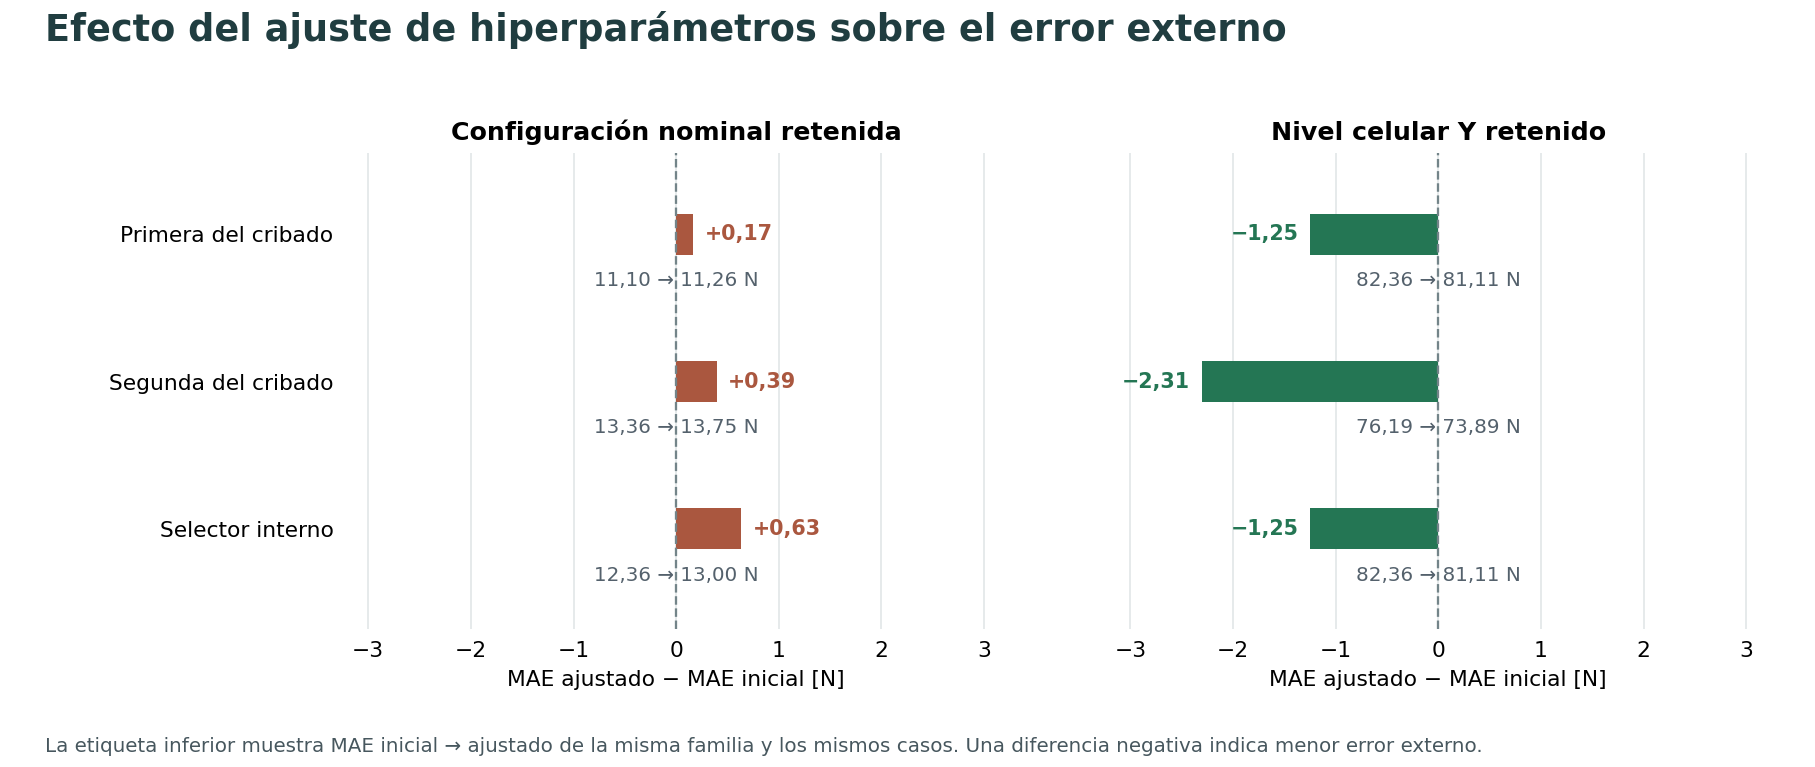

In [74]:
figura(9, _optimizada)

In [75]:
delta_sel = {p:valor(p,"Selector_tuning","delta_MAE_vs_inicial_misma_familia_N") for p in PROTOCOLOS}
frases = {p:("redujo" if v < -1e-9 else "aumentó" if v > 1e-9 else "mantuvo") for p,v in delta_sel.items()}
nota(f"Frente a la misma familia inicial, el ajuste {frases['configuracion']} el MAE "
     f"{fmt(abs(delta_sel['configuracion']))} N por configuración y lo {frases['familia']} "
     f"{fmt(abs(delta_sel['familia']))} N al reservar el nivel.")

Frente a la misma familia inicial, el ajuste aumentó el MAE 0,63 N por configuración y lo redujo 1,25 N al reservar el nivel.

In [76]:
def _estabilidad(data: dict) -> plt.Figure:
    probabilidades = [0.10, 0.25, 0.50, 0.75, 0.90]
    cuadros = []
    for p in PROTOCOLOS:
        folds = _filas(data["folds"], p)
        resumen = (folds.groupby("procedimiento").MAE_validacion_N
                   .quantile(probabilidades).unstack().loc[list(MODELOS)])
        cuadros.append(resumen)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.75), sharey=True)
    upper = max(t.to_numpy().max() for t in cuadros)
    for ax, p, cuadro in zip(axes, PROTOCOLOS, cuadros):
        heat = ax.imshow(cuadro, aspect="auto", cmap="viridis", vmin=0, vmax=upper)
        ax.set(title=PROTO[p], xlabel="Percentil del MAE de los pliegues externos",
               xticks=range(len(probabilidades)), xticklabels=["P10", "P25", "P50", "P75", "P90"],
               yticks=range(len(MODELOS)), yticklabels=[NOMBRES[m] for m in MODELOS])
        ax.tick_params(length=0, pad=5)
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.subplots_adjust(left=0.17, right=0.88, top=0.8, bottom=0.22, wspace=0.12)
    cax = fig.add_axes([0.91, 0.22, 0.016, 0.58])
    fig.colorbar(heat, cax=cax, label="MAE por pliegue [N]")
    _encabezado(fig, 10, "Los percentiles resumen la dispersión entre reservas. Se usa la misma escala en ambos paneles.")
    return fig

#### Figura 10. Estabilidad frente al cambio de reserva

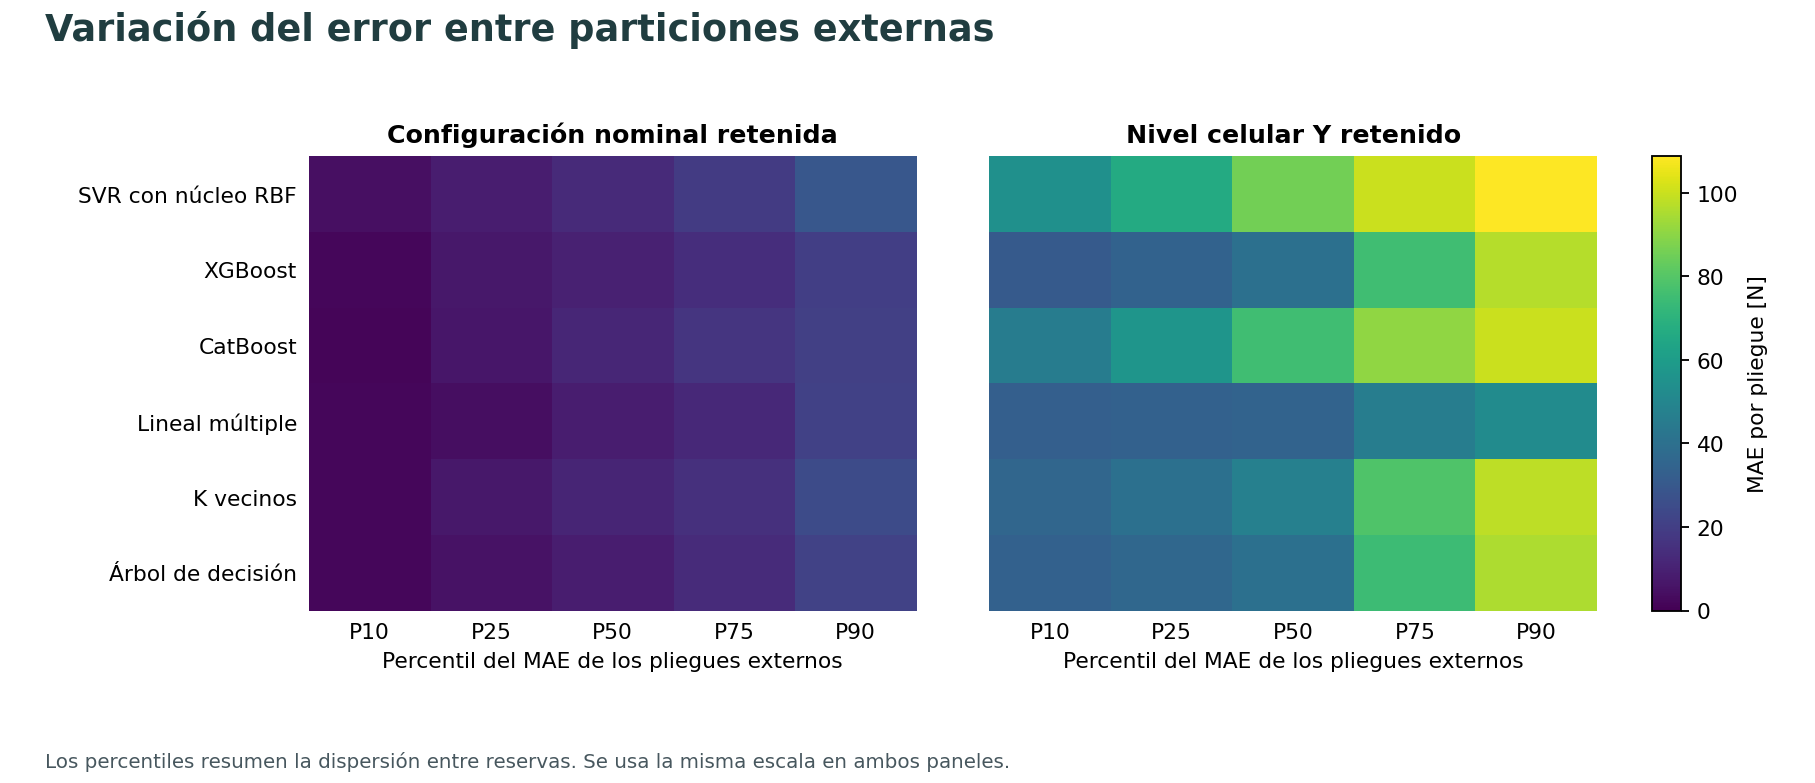

In [77]:
figura(10, _estabilidad)

In [78]:
estable_familia = transferencia.DE_MAE_fold_N.idxmin()
print(f"Menor dispersión del MAE entre configuraciones: {nombre(mas_estable)}, "
      f"{fmt(principal.loc[mas_estable, 'DE_MAE_fold_N'])} N de desviación estándar.")

Menor dispersión del MAE entre configuraciones: Lineal múltiple, 7,91 N de desviación estándar.


### 6.2 Diagnóstico por familia

Se examinan la base lineal y sus pendientes, las distancias a los vecinos y las reglas del árbol. El contraste emparejado usa las mismas reservas para evaluar la sensibilidad de la recomendación.

In [79]:
def _diagnose(obj: Any, family: str, X: pd.DataFrame, Xt: pd.DataFrame, ctx: Params, rows: Rows) -> None:
    """Diagnósticos descriptivos del modelo ajustado; nunca intervienen en el cribado."""
    m = obj.named_steps['model']
    rec = {**ctx, 'familia_real': family, 'n_train': len(X)}
    if 'variance' in obj.named_steps:
        names = list(feature_names(obj))
        rec['n_features_tras_varianza'] = len(names)
    if family == 'Lineal_multiple':
        basis = obj.named_steps['basis']
        scale = obj.named_steps['scale']
        sing = basis.singular_values_
        z = obj[:-2].transform(X)
        zb = basis.transform(z)
        s = np.linalg.svd(zb - zb.mean(axis=0), compute_uv=False)
        keep = [names[i] for i in basis.indices_]
        phys = np.asarray(m.coef_) / scale.scale_[basis.indices_]
        intercept = float(m.intercept_ - np.dot(phys, scale.mean_[basis.indices_]))
        rec.update(rango_centrado=basis.rank_, rango_base=len(keep),
            condicion_centrada=float('inf') if basis.rank_ < len(names) else sing[0] / sing[-1],
            condicion_base=s[0] / s[-1], variables_base=';'.join(keep), intercepto_fisico_N=intercept,
            tol_svd=basis.tol_, singulares_centrados_json=_object(sing.tolist()))
        for c in GEOMETRY:
            i = keep.index(c) if c in keep else None
            rows['coeficientes_ols'].append({**ctx, 'variable': c, 'unidad_variable': UNITS[c],
                'estado': 'retenida' if i is not None else 'redundante_en_train' if c in names else 'constante_en_train', 'coeficiente_N_por_unidad': phys[i] if i is not None else np.nan, 'coeficiente_estandarizado_N': m.coef_[i] if i is not None else np.nan, 'intercepto_fisico_N': intercept})
        np.testing.assert_allclose(intercept + X[keep].to_numpy() @ phys, obj.predict(X), atol=1e-07, rtol=1e-10)
    elif family == 'SVR_RBF':
        rec.update(n_vectores_soporte=len(m.support_), fraccion_vectores_soporte=len(m.support_) / len(X),
            casos_soporte=_ids(X.index[m.support_]))
    elif family == 'KNN':
        dist, idx = m.kneighbors(obj[:-1].transform(Xt))
        for case, ds, ix in zip(Xt.index, dist, idx):
            for i, (d, j) in enumerate(zip(ds, ix), 1):
                rows['vecinos_knn'].append({**ctx, 'Case_n': int(case), 'orden_vecino': i,
                    'caso_vecino_train': int(X.index[j]), 'distancia_escalada': float(d), 'p': m.p,
                    'weights': m.weights})
        rec.update(k=m.n_neighbors, distancia_media_vecinos=float(dist.mean()))
    elif family == 'Arbol_decision':
        rec.update(profundidad=m.get_depth(), hojas=m.get_n_leaves())
        rows['reglas_arbol'].append({**ctx,
            'regla_descriptiva_train': export_text(m, feature_names=names, decimals=6)})
    elif family == 'Media_por_nivel':
        rec.update(n_fallback_test=int((~Xt.n_cells_Y.isin(m.means_)).sum()), media_global_train_N=m.global_mean_)
    rows['diagnosticos_modelos'].append(rec)

In [80]:
for obj, familia, tr, te, contexto in ajustes_para_diagnostico:
    _diagnose(obj, familia, X.iloc[tr], X.iloc[te], contexto, rows)
for clave in ("diagnosticos_modelos", "coeficientes_ols", "reglas_arbol", "vecinos_knn"):
    frames[clave] = pd.DataFrame(rows[clave])

In [81]:
def contraste(oof: pd.DataFrame, candidate: str, base: str) -> dict[str, Any]:
    """Errores emparejados y sensibilidad al grupo en un solo protocolo."""
    if oof.protocolo.nunique()!=1:
        raise ValueError("Comparar un protocolo por vez")
    cols=["Case_n","fold","observado_N","predicho_N"]
    a=oof[oof.procedimiento.eq(candidate)][cols].copy()
    b=oof[oof.procedimiento.eq(base)][cols].copy()
    p=a.merge(b,on=["Case_n","fold"],suffixes=("_a","_b"),validate="one_to_one")
    if len(p)!=len(a) or len(p)!=len(b) or not len(p):
        raise ValueError("Cobertura OOF desigual")
    y=p.observado_N_a.to_numpy()
    if not np.allclose(y,p.observado_N_b,atol=1e-12,rtol=0):
        raise ValueError("Respuesta no comparable")
    ea=np.abs(p.predicho_N_a-y);eb=np.abs(p.predicho_N_b-y)
    d=pd.Series(ea-eb,index=p.index)
    gm=d.groupby(p.fold).mean()
    omit=np.array([d[p.fold.ne(f)].mean() for f in gm.index])
    return {"delta_MAE_N":float(d.mean()),"delta_RMSE_N":float(np.sqrt(np.mean(ea**2))-np.sqrt(np.mean(eb**2))),
            "grupos_mejora":int((gm < -1e-10).sum()),"grupos_empate":int((gm.abs()<=1e-10).sum()),
            "grupos":len(gm),"fraccion_grupos_mejora":float((gm < -1e-10).mean()),
            "delta_al_omitir_grupo_min_N":float(omit.min()),"delta_al_omitir_grupo_max_N":float(omit.max())}


def adopta(c: dict[str,Any], margin: float) -> bool:
    return (c["delta_MAE_N"] <= -margin+1e-10 and c["delta_RMSE_N"] <= 1e-10 and
            c["fraccion_grupos_mejora"]>0.5 and c["delta_al_omitir_grupo_max_N"] < -1e-10)

In [82]:
def lectura_en_memoria(frames, receta, cfg, politica):
    """Distingue menor MAE, recomendación registrada y alternativas no lineales."""
    oof = frames["predicciones_oof"]
    metrics = frames["metricas_resumen"]
    nominal = oof[oof.protocolo.eq("configuracion")]
    m = metrics[metrics.protocolo.eq("configuracion")].set_index("procedimiento")
    f = metrics[metrics.protocolo.eq("familia")].set_index("procedimiento")
    modelos = politica["modelos_iniciales"]
    banda = politica["banda_descriptiva_N"]
    minimo = m.loc[modelos, "MAE_N"].min()
    fijo = next(x for x in politica["prioridad_parsimonia_en_banda"] if m.loc[x,"MAE_N"] <= minimo+banda+1e-10)
    comparacion = contraste(nominal, "Selector_tuning", fijo)
    principal = "Selector_tuning" if adopta(comparacion, banda) else fijo
    frente_a_media = contraste(nominal, principal, "Media_por_nivel")
    operativa = principal if adopta(frente_a_media, banda) else "Media_por_nivel"
    es_selector = principal == "Selector_tuning"
    familia = receta["selector"]["familia_real"] if es_selector else principal
    parametros = receta["selector"]["parametros"] if es_selector else cfg["parametros_iniciales"][principal]
    respaldos = [x for x in m.loc[modelos].sort_values("MAE_N").index if x != familia][:2]
    estrategias = modelos + ["Tuning_rango_1","Tuning_rango_2","Selector_tuning"]
    categorias = {"lineal":"Lineal_multiple","distancias":"KNN",
        "arboles":m.loc[["Arbol_decision","XGBoost","CatBoost"],"MAE_N"].idxmin(),
        "grupo_A_literatura":m.loc[["SVR_RBF","XGBoost","CatBoost"],"MAE_N"].idxmin(),
        "menor_MAE_inicial":m.loc[modelos,"MAE_N"].idxmin(),
        "menor_DE_entre_iniciales":m.loc[modelos,"DE_MAE_fold_N"].idxmin(),
        "menor_MAE_procedimientos_incluido_tuning":m.loc[estrategias,"MAE_N"].idxmin(),
        "menor_MAE_toda_tabla_incluidos_controles":m.MAE_N.idxmin(),"compromiso":principal}
    return {"procedimiento_principal":principal, "familia_principal":familia,
        "parametros_principal":parametros,"respaldos":respaldos,"referencia_operativa":operativa,
        "motivo":"Política de comparación declarada: banda de MAE, dispersión y contraste emparejado por grupo.",
        "MAE_principal_N":float(m.loc[principal,"MAE_N"]), "MAE_media_nivel_N":float(m.loc["Media_por_nivel","MAE_N"]),
        "MAE_referencia_familia_excluida_N":float(f.loc[operativa,"MAE_N"]),
        "MAE_principal_familia_excluida_N":float(f.loc[principal,"MAE_N"]),
        "familia_con_menor_MAE_transferencia":f.loc[modelos,"MAE_N"].idxmin(), "categorias":categorias,
        "procedimiento_fijo_preferido":fijo,"selector_vs_fijo":comparacion,"principal_vs_media_nivel":frente_a_media}

recomendacion = lectura_en_memoria(frames, receta, CFG, LECTURA)

In [83]:
diag = frames["diagnosticos_modelos"]
coef = frames["coeficientes_ols"]
ol = diag[diag.procedimiento.eq("Lineal_multiple") & diag.protocolo.eq("configuracion")]
co = coef[coef.protocolo.eq("configuracion") & coef.estado.eq("retenida")]
coef_resumen = co.groupby(["variable","unidad_variable"]).coeficiente_N_por_unidad.agg(["min","median","max"]).reset_index()
detalle("Pendientes OLS en unidades originales por pliegue", coef_resumen.rename(columns={"min":"Pendiente mínima","median":"Pendiente mediana","max":"Pendiente máxima"}))
mejor_nl = principal.drop(index="Lineal_multiple").MAE_N.idxmin()
d_nl = principal.loc[mejor_nl,"MAE_N"]-principal.loc["Lineal_multiple","MAE_N"]
print("Las pendientes se expresan en la base independiente de cada entrenamiento. "
      "La colinealidad limita su interpretación como efectos físicos individuales.")

**Pendientes OLS en unidades originales por pliegue**

| variable | unidad_variable | Pendiente mínima | Pendiente mediana | Pendiente máxima |
| :--- | :--- | ---: | ---: | ---: |
| Fiber_base | mm | 2,817 | 10,097 | 19,979 |
| Fiber_height | mm | -9,535 | 0,034 | 12,101 |
| Fiber_total_length | mm | 0,985 | 1,080 | 1,147 |
| Fiber_total_volume | mm³ | 0,221 | 0,258 | 0,282 |
| Pivot_height | mm | -6,767 | 7,185 | 18,777 |
| Sample_total_volume | mm³ | -0,130 | -0,107 | -0,079 |
| n_cells_Y | conteo | -491,441 | -456,683 | -403,235 |

Las pendientes se expresan en la base independiente de cada entrenamiento. La colinealidad limita su interpretación como efectos físicos individuales.


In [84]:
cat = recomendacion["categorias"]
detalle("Comparación por familia y estabilidad", pd.DataFrame([{"Categoría del protocolo principal":k.replace("_"," "), "Procedimiento":nombre(v)} for k,v in cat.items()]))
kn_diag = diag[(diag.procedimiento=="KNN") & diag.protocolo.isin(PROTOCOLOS)].groupby("protocolo").distancia_media_vecinos.mean()
tree_diag = diag[(diag.procedimiento=="Arbol_decision") & (diag.protocolo=="configuracion")]
d_kn = valor("configuracion","KNN")-valor("configuracion","Dummy_mediana")
print(f"Distancia media a los vecinos en geometría estandarizada: {fmt(kn_diag['configuracion'])} por "
      f"configuración, {fmt(kn_diag['familia'])} por nivel. El árbol inicial tuvo "
      f"entre {int(tree_diag.hojas.min())} y {int(tree_diag.hojas.max())} hojas en configuraciones.")

**Comparación por familia y estabilidad**

| Categoría del protocolo principal | Procedimiento |
| :--- | :--- |
| lineal | Lineal múltiple |
| distancias | K vecinos |
| arboles | Árbol de decisión |
| grupo A literatura | XGBoost |
| menor MAE inicial | Lineal múltiple |
| menor DE entre iniciales | Lineal múltiple |
| menor MAE procedimientos incluido tuning | Lineal múltiple |
| menor MAE toda tabla incluidos controles | Lineal múltiple |
| compromiso | Lineal múltiple |

Distancia media a los vecinos en geometría estandarizada: 1,72 por configuración, 4,43 por nivel. El árbol inicial tuvo entre 4 y 4 hojas en configuraciones.


In [85]:
mejor_trans = recomendacion["familia_con_menor_MAE_transferencia"]
proc = recomendacion["procedimiento_principal"]
por_caso = oof[(oof.protocolo=="configuracion") & oof.procedimiento.eq(proc)].sort_values("error_absoluto_N",ascending=False)
alto = por_caso.iloc[0]
mae_sin_alto = por_caso.iloc[1:].error_absoluto_N.mean()
print(f"Sensibilidad del MAE de {nombre(proc)}: al omitir del promedio la observación con mayor error "
      f"pasa de {fmt(por_caso.error_absoluto_N.mean())} a {fmt(mae_sin_alto)} N. Se conservaron todas las probetas.")

Sensibilidad del MAE de Lineal múltiple: al omitir del promedio la observación con mayor error pasa de 9,66 a 8,84 N. Se conservaron todas las probetas.


### 6.3 Decisión para la siguiente campaña

La regla de selección favorece la receta más sencilla dentro de 1 N del menor MAE nominal. Adoptar el selector ajustado exige reducir el MAE al menos 1 N, mantener o reducir el RMSE, mejorar en más de la mitad de las configuraciones y conservar la ventaja al retirar cualquiera de ellas del promedio. Se aplica el mismo contraste frente a la media por nivel. La representación A y la regla se valoraron con esta campaña. La confirmación requiere probetas adicionales y un error admisible acordado con el equipo experimental.

In [86]:
prim = recomendacion["procedimiento_principal"]
fam = recomendacion["familia_principal"]
op = recomendacion["referencia_operativa"]
backups = recomendacion["respaldos"]
sel_completa = receta["selector"]
detalle("Receta reajustada con toda la campaña para uso posterior", pd.DataFrame([{
    "Familia": nombre(sel_completa["familia_real"]), "ID": sel_completa["config_id"],
    "Parámetros": json.dumps(sel_completa["parametros"], ensure_ascii=False, sort_keys=True)}]))

**Receta reajustada con toda la campaña para uso posterior**

| Familia | ID | Parámetros |
| :--- | :--- | :--- |
| Árbol de decisión | Arbol_decision_00 | {"criterion": "squared_error", "max_depth": 2, "min_samples_leaf": 2, "random_state": 42} |

In [87]:
# Escoger el contraste no lineal a partir de las mismas predicciones iniciales.
orden_no_lineal = principal.drop(index="Lineal_multiple").sort_values("MAE_N", kind="stable")
mejor_no_lineal, respaldo_no_lineal = orden_no_lineal.index[:2]
comparacion = recomendacion["principal_vs_media_nivel"]
nota(f"Para niveles conocidos, la referencia operativa es {nombre(op)}. "
     f"{nombre(prim)} reduce su MAE en {fmt(-comparacion['delta_MAE_N'])} N. "
     f"Entre las opciones no lineales, {nombre(mejor_no_lineal)} obtiene el menor MAE "
     f"({fmt(valor('configuracion', mejor_no_lineal))} N), seguido de {nombre(respaldo_no_lineal)} "
     f"({fmt(valor('configuracion', respaldo_no_lineal))} N).")

Para niveles conocidos, la referencia operativa es Media por nivel Y. Lineal múltiple reduce su MAE en 0,46 N. Entre las opciones no lineales, Árbol de decisión obtiene el menor MAE (10,96 N), seguido de XGBoost (11,75 N).

In [88]:
# Las tres tablas de la portada proceden de las predicciones de este kernel.
m_portada = frames["metricas_resumen"].set_index(["protocolo", "procedimiento"])
cfg_portada = m_portada.loc["configuracion"]
nivel_portada = m_portada.loc["familia"]

def numeros_iniciales(modelos, etiqueta):
    tabla = cfg_portada.loc[list(modelos), ["MAE_N", "RMSE_N", "R2_OOF"]].copy()
    tabla.columns = ["MAE [N]", "RMSE [N]", "R²"]
    tabla["MAE nivel Y [N]"] = nivel_portada["MAE_N"]
    tabla = tabla.sort_values("MAE [N]").rename(index=NOMBRES)
    return tabla.rename_axis(etiqueta).reset_index()

modelos_portada = numeros_iniciales(MODELOS, "Modelo")
bases_portada = numeros_iniciales(REFS, "Referencia")

# Para cada caso se conserva la misma familia antes y después de ajustar parámetros.
estrategias = ["Tuning_rango_1", "Tuning_rango_2", "Selector_tuning"]
oof_portada = frames["predicciones_oof"]
pareados = oof_portada[oof_portada.procedimiento.isin(estrategias)].copy()
pareados["inicial"] = (pareados.predicho_inicial_misma_familia_N - pareados.observado_N).abs()
pareados["ajustada"] = (pareados.predicho_N - pareados.observado_N).abs()
mae_pareado = pareados.groupby(["procedimiento", "protocolo"])[["inicial", "ajustada"]].mean()
antes_despues = pd.concat([mae_pareado.xs(p, level="protocolo") for p in ("configuracion", "familia")], axis=1)
antes_despues.columns = ["Config. inicial [N]", "Config. ajustada [N]", "Nivel Y inicial [N]", "Nivel Y ajustada [N]"]
tabla_tuning = antes_despues.loc[estrategias].rename(index=NOMBRES).rename_axis("Procedimiento").reset_index()

cambio = mae_pareado.loc[("Selector_tuning", "configuracion")]
delta = cambio.ajustada - cambio.inicial
efecto = "aumentó" if delta > 0 else "disminuyó" if delta < 0 else "se mantuvo"
nota_tuning = (f"Al reservar configuraciones, el MAE del selector {efecto}"
               + (f" en {abs(delta):.3f} N".replace(".", ",") if delta else "") + ".")

portada_resultados.update(Markdown("\n\n".join([
    "MAE, RMSE y R² corresponden a configuraciones reservadas. La última columna mide el error "
    "al retirar un nivel celular Y completo.",
    "### Seis modelos con parámetros iniciales",
    tabla_markdown(modelos_portada),
])))
panel_comparaciones.update(Markdown("\n\n".join([
    "### Baselines",
    tabla_markdown(bases_portada),
    "### MAE antes y después del ajuste de hiperparámetros",
    "Las columnas inicial y ajustada comparan la misma familia sobre las mismas probetas.",
    tabla_markdown(tabla_tuning),
    nota_tuning,
])))

## 7. Reproducir el análisis

Para recalcular las tablas y las gráficas, abre el archivo en Jupyter con un kernel de Python y selecciona **Reiniciar el kernel y ejecutar todo**. Las entradas y los pliegues están incluidos en el cuaderno. `frames["predicciones_oof"]` reúne la carga observada y su predicción fuera de muestra. `frames["seleccion_tuning"]` permite consultar los parámetros elegidos dentro de cada entrenamiento.

In [89]:
def contrastar_historico(historico_oof, rows):
    old = historico_oof.copy()
    if "modelo" not in old:
        old["modelo"] = old["procedimiento"].replace({"Ridge_historico":"Ridge"})
    if "predicho_historico_N" in old:
        old["predicho_N"] = old["predicho_historico_N"]
    if "representacion" in old:
        old = old.loc[old.representacion == "A"]
    old = old[["protocolo","fold","Case_n","modelo","predicho_N"]]
    now = pd.DataFrame(rows["predicciones_oof"])
    for proc, label in [("Ridge_historico","Ridge"),("SVR_RBF","SVR_RBF")]:
        pairs = now.loc[now.procedimiento == proc].merge(
            old.loc[old.modelo == label], on=["protocolo","fold","Case_n"],
            suffixes=("_nuevo","_historico"), validate="one_to_one")
        assert len(pairs) == len(now.loc[now.procedimiento == proc]) == len(old.loc[old.modelo == label])
        np.testing.assert_allclose(pairs.predicho_N_nuevo, pairs.predicho_N_historico, atol=1e-9, rtol=1e-12)
        for r in pairs.itertuples():
            rows["invariancia_historica"].append({
                "protocolo": r.protocolo, "fold": r.fold, "Case_n": r.Case_n, "procedimiento": proc,
                "predicho_N": r.predicho_N_nuevo, "predicho_historico_N": r.predicho_N_historico,
                "diferencia_N": r.predicho_N_nuevo-r.predicho_N_historico,
            })

contrastar_historico(historico_oof, rows)
frames["invariancia_historica"] = pd.DataFrame(rows["invariancia_historica"])